# Détection de messages malveillants — classification binaire supervisée

## 0. Comprendre le phishing

### 0.1 C'est quoi ?
Le **phishing** (hameçonnage), c'est une **arnaque par message** (email, SMS, WhatsApp, etc.).  
L'attaquant se fait passer pour quelqu'un de confiance : banque, collègue, support IT, service de livraison, administration…

### 0.2 Quel est l'objectif de l'attaquant ?
L'objectif est de te faire faire une action qui lui profite, par exemple :
- **Voler tes identifiants** : mot de passe, code, compte.
- **Voler de l'argent** : faux paiement, faux virement.
- **Installer un malware** : via un lien ou une pièce jointe.
- **Entrer dans l'entreprise** : récupérer un accès pour aller plus loin.

### 0.3 Comment fonctionne la logique (étape par étape)
1. **Appât** : l'attaquant envoie un message crédible. Ex. : « Votre compte sera bloqué », « Facture urgente ».
2. **Pression** : il crée l'urgence ou la peur pour que tu agisses vite sans vérifier.
3. **Piège** : le message contient un lien, une pièce jointe, ou demande une information sensible.
4. **Action de la victime** : tu cliques, ouvres, réponds, ou donnes tes informations.
5. **Résultat** : l'attaquant récupère ce qu'il voulait (accès, argent, données).

### 0.4 Exemple concret
> « Votre compte sera désactivé dans 1 heure. Cliquez ici pour vérifier. »

- Tu cliques sur le lien.
- Tu arrives sur un faux site qui ressemble au vrai.
- Tu entres ton mot de passe.
- L'attaquant récupère ton mot de passe.

### 0.5 Pourquoi l'IA rend le phishing plus difficile à repérer
Avant : fautes, texte bizarre, message générique.  
Avec l'IA, un message peut être bien écrit, personnalisé, adapté au ton d'un collègue/service, donc plus crédible. Les anciens signes seuls ne suffisent plus.

### 0.6 Lien avec le projet (logique du modèle)
Le modèle ne « lit » pas comme un humain. Il regarde des **signaux/variables** et combine ces signaux pour estimer une probabilité : **malveillant (Oui)** ou **normal (Non)**.  
C'est une **aide à la décision** : un humain doit vérifier avant de bloquer/supprimer.


## 1. Données, objectif et cadre méthodologique

**Jeu de données synthétique** généré localement pour ce mini-projet (ISCAE Master VIC). Il ne contient **aucun vrai e-mail, aucune donnée personnelle et aucune source externe** à citer. Les performances mesurées ici ne doivent donc **pas** être présentées comme des résultats obtenus sur de vraies campagnes de phishing.

**Objectif — pré-dépistage.** Le modèle trie rapidement les messages pour repérer ceux qui sont suspects.

- **Entrée** : les signaux du message (urgence, liens, âge du domaine, expéditeur connu, etc.).
- **Sortie** : `Oui` (suspect/malveillant) ou `Non` (normal), avec une probabilité.
- **Exemple** : `urgence_score=9`, `nb_liens=5`, `domaine_age_jours=3`, `expediteur_connu=0`, `piece_jointe=1` → le modèle peut prédire **Oui**.

Le résultat est une **aide à la décision** : la vérification finale reste humaine. Aucun message n'est supprimé automatiquement.

**Règle méthodologique appliquée dans tout le notebook.** La séparation train / test est définie au §8, **avant toute statistique descriptive**. Les analyses qui peuvent orienter la modélisation (corrélations, associations, moyennes par classe) sont donc calculées sur le **train seul (416 messages)** ; le test (104 messages) n'est lu qu'au §16 et au §18, pour mesurer. Les contrôles de qualité (types, doublons, valeurs manquantes) portent en revanche sur le fichier brut complet : ils ne servent pas à choisir un modèle.


## 2. Comment choisir un modèle ?

### 2.1 Le contexte
On veut détecter les messages **malveillants (phishing IA)**. Les classes sont déséquilibrées : **374 `Non` / 146 `Oui`** après déduplication. L'erreur la plus grave est le **faux négatif** : un message malveillant prédit `Non`.

### 2.2 Les critères de choix
- **F1 macro** : critère principal, car il donne le même poids aux deux classes malgré le déséquilibre.
- **Rappel de la classe `Oui`** : mesure combien de malveillants sont réellement détectés.
- **Précision / faux positifs** : à surveiller pour éviter de saturer l'analyste.
- **AUC et AP** : qualité du classement, indépendante d'un seuil particulier.
- **Matrice de confusion** : montre les FN et FP en nombres concrets.
- **Simplicité / interprétabilité** : utile pour expliquer une décision à un humain.

### 2.3 Les modèles comparés
| Modèle | Intérêt | Limite |
|---|---|---|
| Régression logistique | Simple, interprétable | Peut rater des relations non linéaires |
| Random Forest | Bon sur les relations non linéaires, robuste | Moins simple à expliquer |
| SVM noyau RBF | Marge maximale, stable en validation croisée | Moins interprétable, plus lent |

### 2.4 La règle de décision (à retenir)
1. Le modèle est choisi **sur le train uniquement**, par validation croisée (§15).
2. Le modèle retenu est ensuite **spécialisé** (`log_age`, interactions) et son **seuil** est appris sur les probabilités hors pli du train (§17).
3. Le **test** n'est lu qu'ensuite, une seule fois, pour mesurer (§16 et §18). La comparaison des trois modèles de référence sur le test est donc **descriptive** : elle n'entre pas dans la sélection.


**Mini-projet 3 — Veille stratégique : IA et confiance numérique**

## 3. Contexte, problématique, dictionnaire des colonnes et feuille de route

### 3.1 Contexte
L'IA générative écrit des messages de phishing sans fautes et avec un ton personnalisé. Les signes classiques (fautes de langue, style maladroit) deviennent donc moins fiables. Un responsable sécurité (RSSI) doit pourtant décider, parmi les messages reçus, lesquels méritent une analyse approfondie. Les 524 lignes du fichier sont **synthétiques** : aucune donnée personnelle, aucun vrai e-mail.

### 3.2 Problématique
> **Comment détecter un message malveillant quand les signes classiques deviennent moins fiables à cause de l'IA, et comment garder un niveau d'alerte explicable ?**

La cible `message_malveillant` est binaire (`Non` / `Oui`), avec **374 `Non` pour 146 `Oui`** après suppression des doublons. L'accuracy seule est trompeuse (prédire toujours `Non` donne déjà ~72 %) : on regarde surtout le **rappel** et le **F1** de la classe `Oui`.

### 3.3 Quelle erreur coûte le plus cher ?
Le **faux négatif** : un message malveillant classé `Non` passe les filtres et peut déclencher une compromission. Le faux positif (message légitime signalé) coûte du temps à l'analyste mais se corrige par validation humaine. On peut donc **baisser le seuil de décision** pour gagner en rappel, en acceptant plus de faux positifs — ce compromis est étudié au §17.

### 3.4 Dictionnaire des colonnes

Un message avec un domaine récent peut mériter une vérification supplémentaire : un âge faible est un indice de risque potentiel, jamais une preuve. Le problème est formulé comme une classification binaire à partir d'indicateurs déjà extraits, pas comme une analyse du contenu, des liens ou de la réputation en temps réel.

| Colonne | Sens interprété | Utilisation |
|---|---|---|
| `date` | Date associée au message | EDA seulement ; exclue des prédicteurs pour éviter d'apprendre une tendance calendaire propre à ce petit échantillon. |
| `heure_envoi` | Heure d'envoi, de 0 à 23 | Prédicteur numérique ; relation potentiellement non linéaire avec le risque. |
| `longueur_message` | Longueur du message (unité non précisée) | Prédicteur ; ne révèle pas à elle seule le caractère malveillant. |
| `nb_liens` | Nombre de liens | Prédicteur ; ne renseigne pas sur la destination ni la sûreté du lien. |
| `urgence_score` | Score d'urgence, 0–10 | Prédicteur ; échelle supposée d'après les valeurs observées. |
| `domaine_age_jours` | Âge du domaine en jours | Prédicteur ; un âge faible peut être un signal, pas une preuve. 10 valeurs manquantes. |
| `fautes_langue` | Nombre d'erreurs linguistiques | Prédicteur ; peut refléter le bruit, la langue ou la qualité de saisie. |
| `expediteur_connu` | Indicateur 0/1 de familiarité | Prédicteur binaire ; définition métier à confirmer avec l'auteur des données. |
| `piece_jointe` | Indicateur 0/1 de présence | Prédicteur binaire ; ne distingue ni le type ni la sûreté du fichier. |
| `personnalisation_score` | Score de personnalisation, 0–10 | Prédicteur ; échelle supposée d'après les valeurs observées. |
| `message_malveillant` | Étiquette `Oui` / `Non` | Cible à prédire ; jamais utilisée comme variable d'entrée. |

Les valeurs des scores et indicateurs sont contrôlées au §6. Les colonnes binaires restent des entiers 0/1. La date est convertie et utilisée pour l'EDA, mais n'entre pas dans le modèle.

### 3.5 Zoom sur `personnalisation_score`

Cet attribut mesure **à quel point un message semble adapté à son destinataire**, au lieu d'être générique.

**Exemple 1 — message générique (score faible)**

> Cher client, votre compte nécessite une vérification. Cliquez ici.

**Exemple 2 — message personnalisé (score plus élevé)**

> Bonjour Faker, votre compte bancaire associé à votre adresse e-mail nécessite une vérification.

**Lecture du score.** Dans ce jeu de données, l'échelle va de **0 à 10** (médiane 5). Bornes illustratives :

| Score | Interprétation |
|---|---|
| 0–2 | Très peu personnalisé |
| 3–4 | Faiblement personnalisé |
| 5–7 | Moyennement personnalisé |
| 8–10 | Fortement personnalisé |

**Rapport avec le phishing (train seul).** Score moyen **4,81** pour `Non`, **5,58** pour `Oui` ; corrélation avec la cible **+0,13** : faible, mais non nulle. Le *spear phishing* exploite des informations personnelles pour gagner la confiance. Attention : **un message très personnalisé n'est pas forcément malveillant** (les banques personnalisent aussi). La variable est conservée, mais elle ne suffit jamais seule : c'est la combinaison avec l'âge du domaine, l'urgence et l'expéditeur inconnu qui produit le verdict.

### 3.6 Comment le modèle prédit-il ? (logique pas à pas)

1. **Séparation d'abord.** Le split 80/20 stratifié (seed 42) est défini au §8, avant toute statistique descriptive. `X` contient les 9 variables explicatives, `y` la cible. Un `assert` vérifie que la cible n'est pas dans `X`.
2. **EDA sur le train.** Corrélations et moyennes par classe sont calculées sur les 416 messages du train : le test ne guide ni le feature engineering ni le choix des variables.
3. **Prétraitement dans le pipeline.** Imputation médiane et standardisation sont ajustées **dans chaque pli d'entraînement**, jamais sur le test.
4. **Comparaison sur le train.** Régression logistique, Random Forest et SVM RBF sont comparés par validation croisée 5-fold sur le train (§15). La baseline majoritaire est écartée : elle prédit toujours `Non` et ne détecte aucune attaque.
5. **Modèle retenu et seuil.** La régression logistique améliorée (`log_age` + interactions) est spécialisée ; son seuil binaire est appris sur les probabilités hors pli du train (§17), pas sur le test.
6. **Explication.** L'importance par permutation est calculée **sur le train** (§19) : elle décrit ce que le modèle utilise, sans relire le test.
7. **Validation humaine.** Une prédiction `Oui` déclenche une vérification, jamais une suppression automatique.

### 3.7 Feuille de route

| Sections | Contenu |
|---|---|
| §4–§7 | Installation, chargement, diagnostic de qualité, nettoyage |
| §8–§9 | Séparation train/test, EDA et corrélations **sur le train seul** |
| §10–§13 | Construction de `X`/`y`, prétraitement, schéma du processus |
| §14–§15 | Modèles candidats, **sélection par validation croisée sur le train** |
| §16–§18 | Comparaison descriptive sur le test, modèle retenu, seuil, évaluation finale |
| §19–§23 | Importance des variables, scénarios, sauvegarde, conclusion, livrables |

Exécuter les cellules dans l'ordre, de haut en bas.


## 4. Installation et importation des bibliothèques

Installer une seule fois les bibliothèques si nécessaire.


In [1]:
# Dans un terminal Jupyter si les bibliothèques ne sont pas installées :
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.base import clone
import joblib

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("Bibliothèques chargées avec succès.")

Bibliothèques chargées avec succès.


## 5. Chargement du fichier

Le CSV doit être dans le même dossier que ce notebook. Les constantes ci-dessous pointent directement sur le seul fichier utilisé.


In [2]:

from pathlib import Path

# Configuration
DATA_PATH = Path("dataset_phishing_ia - dataset_phishing_ia.csv")
TARGET = "message_malveillant"
ORDER = ["Non", "Oui"]

# Vérification du fichier
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Dataset introuvable : {DATA_PATH.resolve()}")

# Chargement des données brutes
df_brut = pd.read_csv(DATA_PATH)

# Vérification de la cible
assert TARGET in df_brut.columns, f"Colonne cible absente : {TARGET}"

# Dimensions
print("Dimensions (lignes, colonnes) :", df_brut.shape)
print("Nombre de variables explicatives :", df_brut.shape[1] - 1)


Dimensions (lignes, colonnes) : (524, 11)
Nombre de variables explicatives : 10


In [3]:
# Dernières lignes
df_brut.tail()


,date,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score,message_malveillant
519,2026-09-29,5,222,1,4,5874.0,1,0,0,6,Non
520,2026-09-30,10,475,4,10,41.0,4,0,0,7,Oui
521,2026-09-30,6,107,0,10,661.0,2,1,1,6,Non
522,2026-09-30,14,509,0,4,1227.0,2,1,0,5,Non
523,2026-09-30,21,507,1,4,800.0,3,0,1,5,Non


In [4]:
df_brut.head()

,date,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score,message_malveillant
0,2026-01-01,19,709,0,4,1133.0,3,0,0,8,Non
1,2026-01-01,22,303,2,6,268.0,2,1,0,6,Non
2,2026-01-03,12,246,0,4,138.0,2,0,0,8,Non
3,2026-01-04,13,355,2,7,790.0,4,1,0,6,Oui
4,2026-01-04,18,235,2,4,323.0,2,1,0,4,Non


In [5]:
# Colonnes
df_brut.columns.tolist()


['date',
 'heure_envoi',
 'longueur_message',
 'nb_liens',
 'urgence_score',
 'domaine_age_jours',
 'fautes_langue',
 'expediteur_connu',
 'piece_jointe',
 'personnalisation_score',
 'message_malveillant']

In [6]:
# Informations générales
df_brut.info()


<class 'pandas.DataFrame'>
RangeIndex: 524 entries, 0 to 523
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   date                    524 non-null    str    
 1   heure_envoi             524 non-null    int64  
 2   longueur_message        524 non-null    int64  
 3   nb_liens                524 non-null    int64  
 4   urgence_score           524 non-null    int64  
 5   domaine_age_jours       514 non-null    float64
 6   fautes_langue           524 non-null    int64  
 7   expediteur_connu        524 non-null    int64  
 8   piece_jointe            524 non-null    int64  
 9   personnalisation_score  524 non-null    int64  
 10  message_malveillant     524 non-null    str    
dtypes: float64(1), int64(8), str(2)
memory usage: 51.8 KB


In [7]:

print("Statistiques descriptives de toutes les variables :")
display(df_brut.describe(include="all").T)

Statistiques descriptives de toutes les variables :


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,524,231,2026-02-22,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
heure_envoi,524.0,NaN,NaN,NaN,12.23855,6.889344,0.0,6.0,13.0,18.0,23.0
longueur_message,524.0,NaN,NaN,NaN,413.225191,162.774765,60.0,301.5,423.0,523.25,896.0
nb_liens,524.0,NaN,NaN,NaN,1.387405,1.165433,0.0,1.0,1.0,2.0,5.0
urgence_score,524.0,NaN,NaN,NaN,4.519084,2.373696,0.0,3.0,4.0,6.0,10.0
domaine_age_jours,514.0,NaN,NaN,NaN,739.330739,761.682914,1.0,217.25,516.0,951.25,5874.0
fautes_langue,524.0,NaN,NaN,NaN,2.020992,1.38744,0.0,1.0,2.0,3.0,6.0
expediteur_connu,524.0,NaN,NaN,NaN,0.44084,0.496962,0.0,0.0,0.0,1.0,1.0
piece_jointe,524.0,NaN,NaN,NaN,0.232824,0.423035,0.0,0.0,0.0,0.0,1.0
personnalisation_score,524.0,NaN,NaN,NaN,4.977099,2.55409,0.0,3.0,5.0,7.0,10.0


In [8]:
print("Nombre de valeurs distinctes par colonne :")
display(df_brut.nunique().sort_values(ascending=False).to_frame("valeurs_uniques"))

print("Valeurs distinctes de la cible :")
print(df_brut[TARGET].value_counts(dropna=False))



Nombre de valeurs distinctes par colonne :


,valeurs_uniques
domaine_age_jours,425
longueur_message,330
date,231
heure_envoi,24
urgence_score,11
personnalisation_score,11
fautes_langue,7
nb_liens,6
expediteur_connu,2
piece_jointe,2


Valeurs distinctes de la cible :
message_malveillant
Non    377
Oui    147
Name: count, dtype: int64


## 6. Diagnostic de qualité : valeurs manquantes et doublons

Ce diagnostic porte sur le **fichier brut complet** : il sert à nettoyer avant la séparation train/test, pas à choisir un modèle. Aucune statistique inferentielle (corrélation, moyenne par classe) n'est tirée de cette étape.


In [9]:
tableau = pd.DataFrame({
    "manquants": df_brut.isna().sum(),
     "% manquants": (df_brut.isna().mean() * 100).round(2)
     })

display(tableau)

nb_doublons = df_brut.duplicated().sum()
print(f"Nombre de lignes dupliquées : {nb_doublons}")
print("Nombre de lignes avant nettoyage :", len(df_brut))

,manquants,% manquants
date,0,0.00
heure_envoi,0,0.00
longueur_message,0,0.00
nb_liens,0,0.00
urgence_score,0,0.00
domaine_age_jours,10,1.91
fautes_langue,0,0.00
expediteur_connu,0,0.00
piece_jointe,0,0.00
personnalisation_score,0,0.00


Nombre de lignes dupliquées : 4
Nombre de lignes avant nettoyage : 524


In [10]:
# Afficher les doublons pour les examiner avant suppression
display(df_brut[df_brut.duplicated(keep=False)].sort_values(by=list(df_brut.columns)).head(20))

,date,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score,message_malveillant
71,2026-02-02,23,283,2,8,574.0,3,0,0,4,Non
72,2026-02-02,23,283,2,8,574.0,3,0,0,4,Non
224,2026-04-26,18,528,0,5,789.0,0,1,0,9,Non
225,2026-04-26,18,528,0,5,789.0,0,1,0,9,Non
330,2026-06-15,4,397,5,7,278.0,1,1,1,2,Oui
331,2026-06-15,4,397,5,7,278.0,1,1,1,2,Oui
458,2026-08-30,17,377,0,3,627.0,3,1,0,4,Non
459,2026-08-30,17,377,0,3,627.0,3,1,0,4,Non


## 7. Nettoyage des données

Le cahier des charges indique que le fichier contient quelques doublons exacts et une colonne numérique avec des valeurs manquantes. On supprime les **4 doublons exacts** (524 → 520 lignes). L'imputation par médiane est faite **dans le pipeline**, donc calculée sur le train de chaque pli : elle ne transmet aucune information issue du test.


In [11]:
df = df_brut.copy()

nb_avant = len(df)
df = df.drop_duplicates().copy()

print('Doublons supprimés :', nb_avant - len(df))
print('Lignes après :', len(df))

Doublons supprimés : 4
Lignes après : 520


In [12]:
assert TARGET in df.columns, f"Cible absente : {TARGET}"
assert df[TARGET].notna().all(), "Valeurs manquantes dans la cible."

print("OK : cible présente et complète.")

OK : cible présente et complète.


In [13]:
# Répartition de la colonne à prédire
df[TARGET].value_counts().to_frame('effectif')


,effectif
message_malveillant,
Non,374
Oui,146


## 8. Analyse exploratoire — distribution de la cible

Les graphiques servent à comprendre le phénomène avant de modéliser ; ils ne prouvent aucune causalité.

*


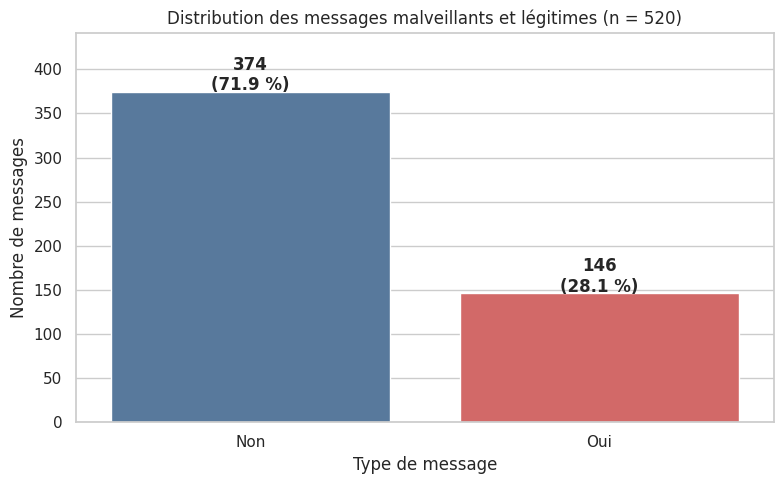

,Effectif,Pourcentage (%)
message_malveillant,,
Non,374,71.92
Oui,146,28.08


In [14]:

# Graphique 1 : distribution de la cible sur le dataset complet

counts = df[TARGET].value_counts().reindex(ORDER, fill_value=0)
pct = counts / counts.sum() * 100

fig, ax = plt.subplots(figsize=(8, 5))

sns.countplot(
    data=df,
    x=TARGET,
    order=ORDER,
    hue=TARGET,
    palette={"Non": "#4C78A8", "Oui": "#E45756"},
    legend=False,
    ax=ax
)

for i, cls in enumerate(ORDER):
    ax.text(
        i,
        counts[cls] + 2,
        f"{counts[cls]}\n({pct[cls]:.1f} %)",
        ha="center",
        fontweight="bold"
    )

ax.set_title("Distribution des messages malveillants et légitimes (n = 520)")
ax.set_xlabel("Type de message")
ax.set_ylabel("Nombre de messages")
ax.set_ylim(0, counts.max() * 1.18)

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Effectif": counts,
    "Pourcentage (%)": pct.round(2)
}))


## Histogrammes — Distribution des variables numériques
### Utilité : comprendre la distribution des variables, leur dispersion, leur asymétrie et leurs valeurs fréquentes.

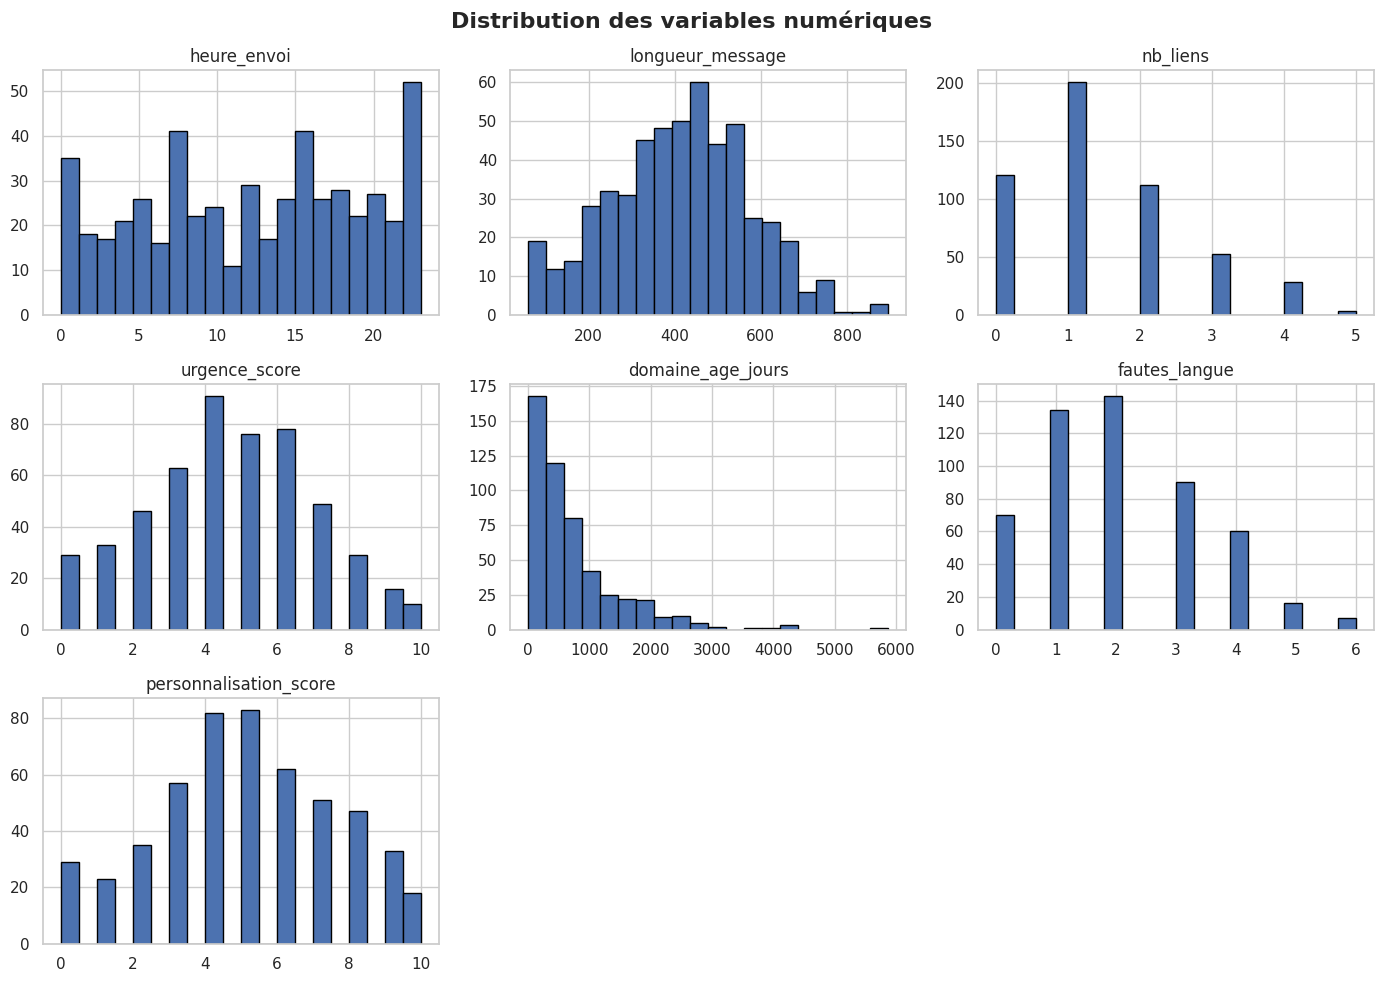

In [15]:
# Graphique 2 : distribution des variables numériques

features = [
    'heure_envoi',
    'longueur_message',
    'nb_liens',
    'urgence_score',
    'domaine_age_jours',
    'fautes_langue',
    'personnalisation_score'
]

df[features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle(
    "Distribution des variables numériques",
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Boxplots — Détection des valeurs extrêmes
### Utilité : identifier les observations éloignées de la distribution habituelle.

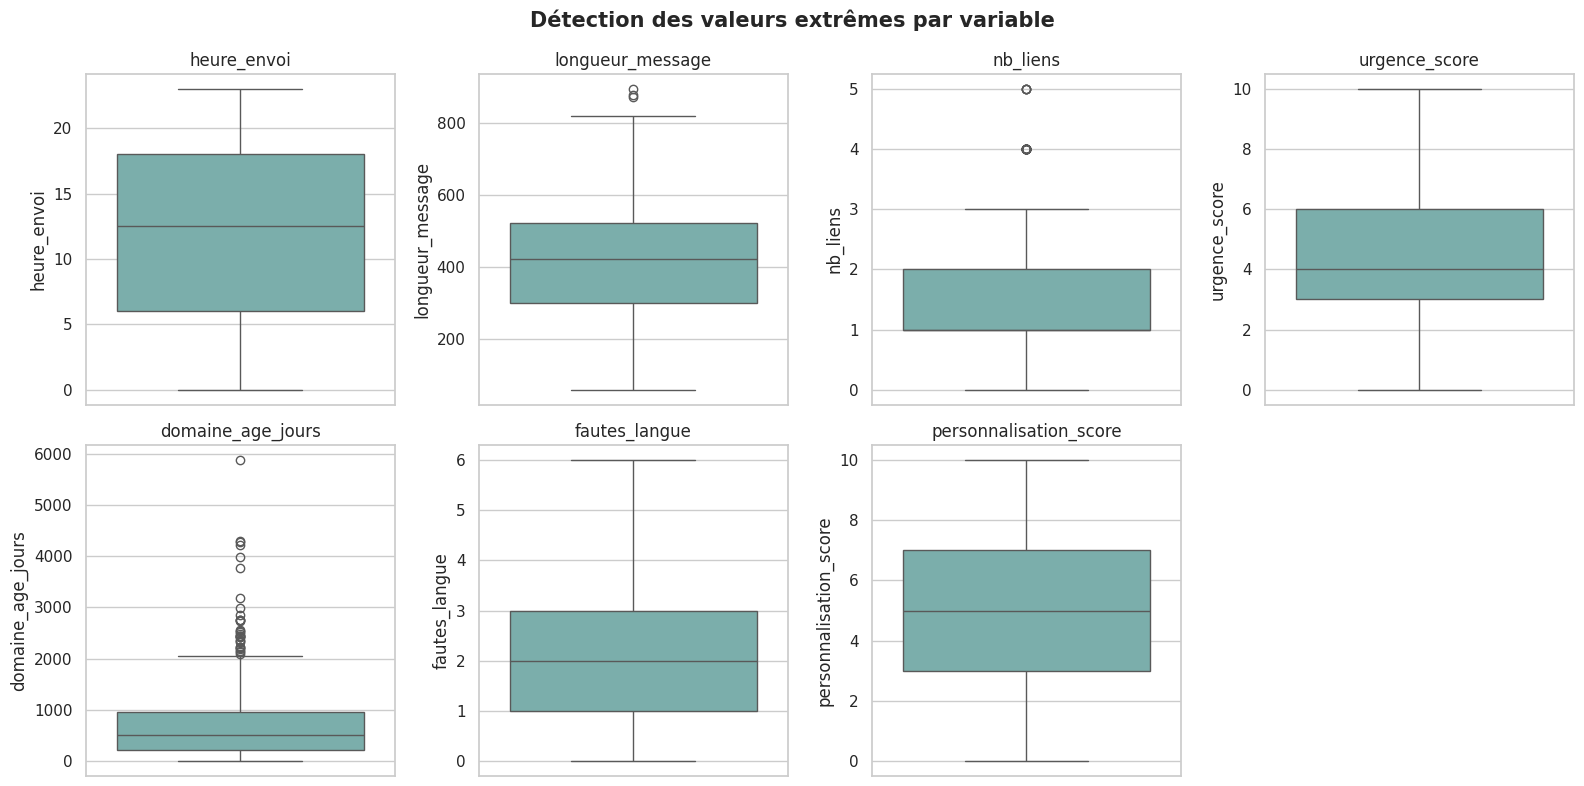

In [16]:
# Graphique 3 : détection des valeurs extrêmes

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(data=df, y=col, color='#72B7B2', ax=axes[i])
    axes[i].set_title(col)

axes[-1].axis('off')

plt.suptitle(
    "Détection des valeurs extrêmes par variable",
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Comparaison des variables selon la cible
### Utilité : observer les différences entre les messages légitimes (Non) et malveillants (Oui).

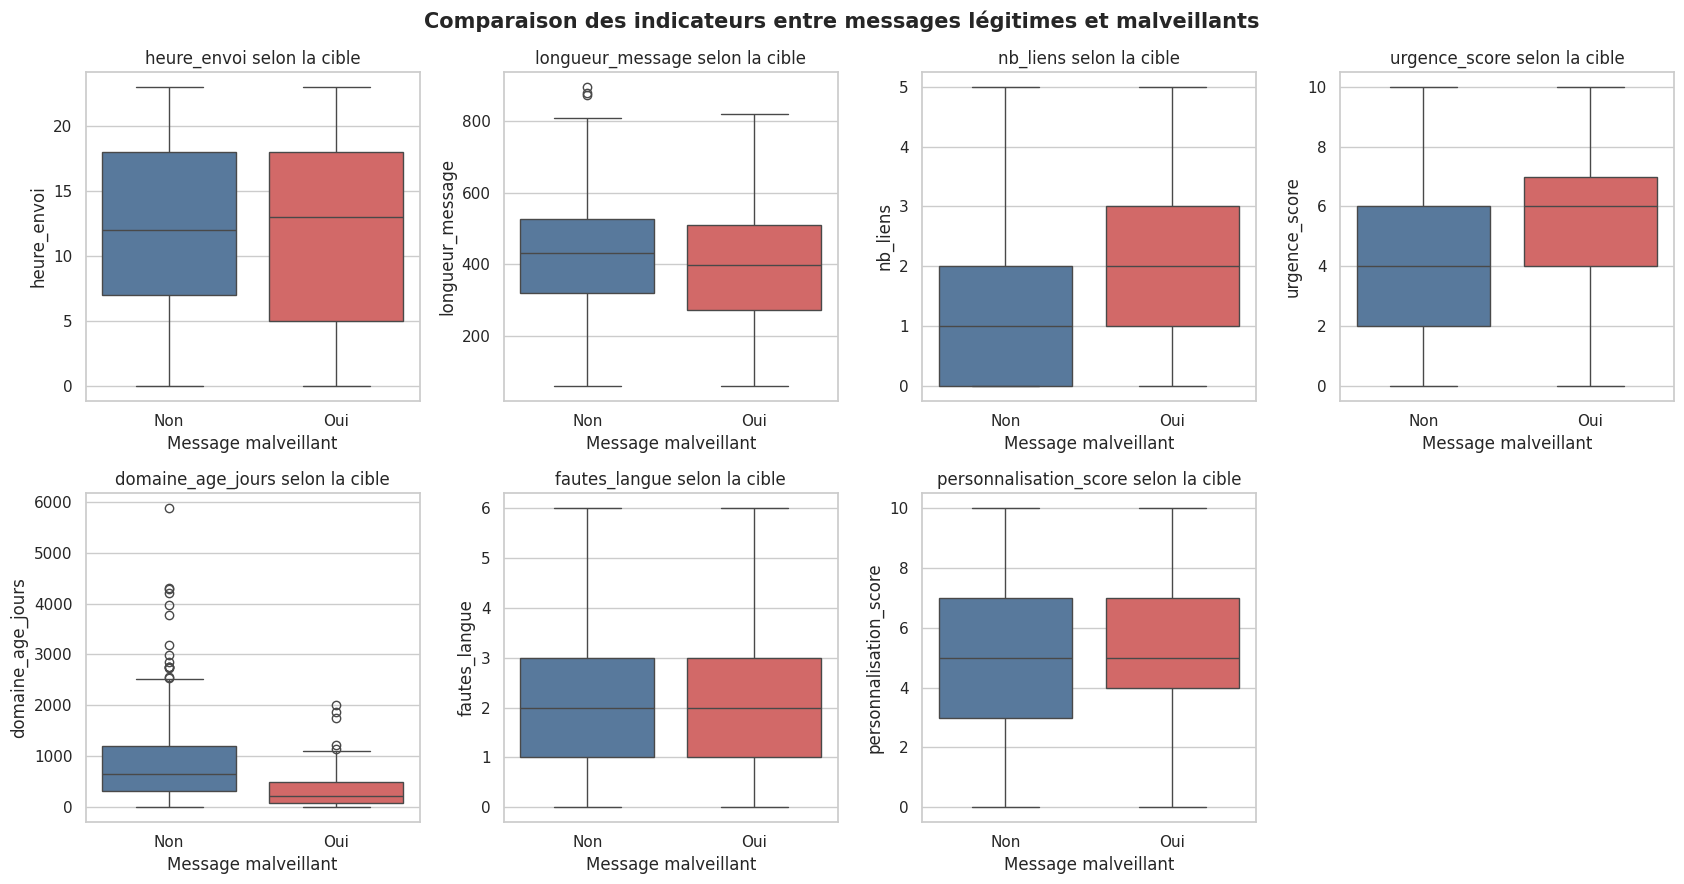

In [17]:
# Graphique 4 : comparaison des variables selon la cible

fig, axes = plt.subplots(2, 4, figsize=(17, 9))
axes = axes.flatten()

for i, col in enumerate(features):
    sns.boxplot(
        data=df,
        x=TARGET,
        y=col,
        order=ORDER,
        hue=TARGET,
        palette={'Non': '#4C78A8', 'Oui': '#E45756'},
        legend=False,
        ax=axes[i]
    )
    axes[i].set_title(f"{col} selon la cible")
    axes[i].set_xlabel("Message malveillant")

axes[-1].axis('off')

plt.suptitle(
    "Comparaison des indicateurs entre messages légitimes et malveillants",
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## . Matrice de corrélation — Relations entre variables
### Utilité : mesurer les relations linéaires entre les variables numériques et identifier les éventuelles redondances.

La corrélation de Pearson mesure une association **linéaire** entre variables numériques. Elle ne s'applique pas directement aux catégories nominales. On encode temporairement la cible pour visualiser une association exploratoire, mais le code numérique des classes n'est pas une distance naturelle. Une corrélation ne signifie jamais causalité.




### Comment lire une matrice de corrélation

**1. La structure** : chaque case croise la variable de sa ligne avec celle de sa colonne. La matrice est symétrique (case A,B = case B,A), donc on lit surtout une moitié.

**2. La diagonale** : toujours 1,00 car une variable est parfaitement corrélée avec elle-même. On l'ignore.

**3. Le nombre (coefficient de Pearson r, entre -1 et +1)**
- `+1` : quand l'une augmente, l'autre augmente.
- `-1` : quand l'une augmente, l'autre diminue.
- `0` : aucun lien linéaire.
- Repères indicatifs : `|r| < 0,3` faible, `0,3 à 0,7` modéré, `> 0,7` fort.

**4. La couleur** : rouge = positif, bleu = négatif, gris clair = proche de 0.




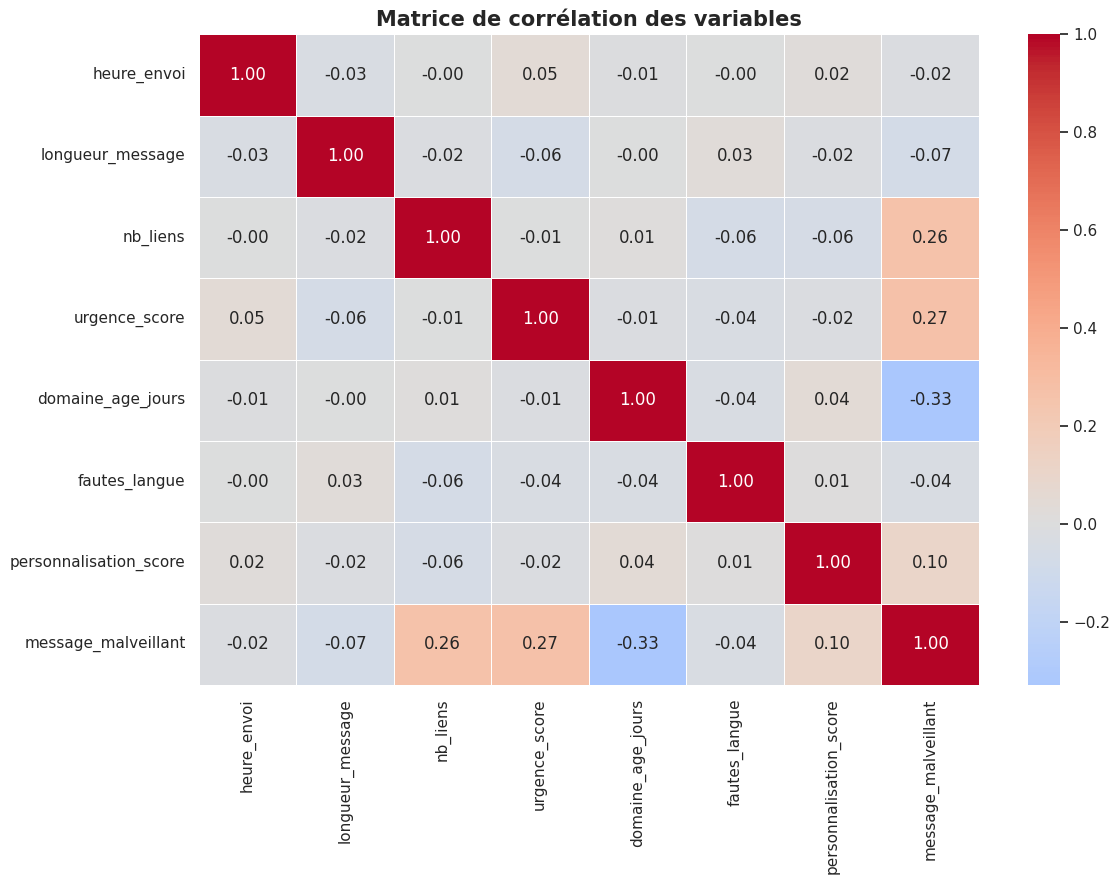

In [18]:
# Graphique 5 : matrice de corrélation

colonnes_corr = features + [TARGET]

df_corr = df[colonnes_corr].copy()

# Encodage temporaire de la cible
df_corr[TARGET] = df_corr[TARGET].map({
    'Non': 0,
    'Oui': 1
})

corr = df_corr.corr(method='pearson')

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5
)

plt.title(
    "Matrice de corrélation des variables",
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

## Graphique 1 — Matrice de corrélation des variables

| Variable | Corrélation avec `message_malveillant` | Interprétation |
|---|---:|---|
| `domaine_age_jours` | -0.33 | Plus le domaine est ancien, moins le message est associé à la classe malveillante. |
| `urgence_score` | +0.27 | Un score d'urgence élevé est associé aux messages malveillants. |
| `nb_liens` | +0.26 | Un nombre élevé de liens est associé à la classe malveillante. |
| `personnalisation_score` | +0.10 | Association positive, mais faible. |
| `longueur_message` | -0.07 | Association très faible et négative. |
| `fautes_langue` | -0.04 | Presque aucune association linéaire. |
| `heure_envoi` | -0.02 | Pas de relation linéaire importante visible. |

### Conclusion du graphique 1

- `domaine_age_jours` présente l'association négative la plus forte avec la cible.
- `urgence_score` et `nb_liens` présentent des associations positives modérées.
- Les autres variables présentent des associations faibles ou presque nulles.
- Les corrélations entre les variables explicatives sont généralement faibles, ce qui indique peu de redondance linéaire apparente.

## Graphique 2 — Association des variables avec la cible (Oui = 1)

| Rang | Variable | Corrélation | Interprétation |
|---:|---|---:|---|
| 1 | `domaine_age_jours` | -0.329 | Les domaines récents sont davantage associés aux messages malveillants. |
| 2 | `urgence_score` | +0.272 | Les messages malveillants présentent davantage de signaux d'urgence. |
| 3 | `nb_liens` | +0.259 | Les messages malveillants sont associés à davantage de liens. |
| 4 | `expediteur_connu` | -0.242 | Un expéditeur connu est davantage associé aux messages légitimes. |
| 5 | `personnalisation_score` | +0.102 | Une personnalisation élevée est légèrement associée aux messages malveillants. |
| 6 | `piece_jointe` | +0.102 | La présence d'une pièce jointe présente une association positive faible. |
| 7 | `longueur_message` | -0.072 | Faible association négative. |
| 8 | `fautes_langue` | -0.035 | Association presque nulle. |
| 9 | `heure_envoi` | -0.017 | Association presque nulle. |

### Interprétation des couleurs

- 🔴 Rouge : association positive avec `Oui` (message malveillant).
- 🔵 Bleu : association négative avec `Oui` (message malveillant).
- Une corrélation proche de zéro indique une faible association linéaire.



### Remarque méthodologique

- Ces corrélations mesurent des associations et non une causalité.
- Une faible corrélation ne signifie pas qu'une variable est inutile pour la prédiction.
- Il est préférable de conserver les neuf variables explicatives au départ, puis d'évaluer leur utilité avec la validation croisée et les performances du modèle.

## l'association de chaque variable explicative avec la classe malveillante (Oui).

,correlation_avec_Oui
domaine_age_jours,-0.329
urgence_score,0.272
nb_liens,0.259
expediteur_connu,-0.242
personnalisation_score,0.102
piece_jointe,0.102
longueur_message,-0.072
fautes_langue,-0.035
heure_envoi,-0.017


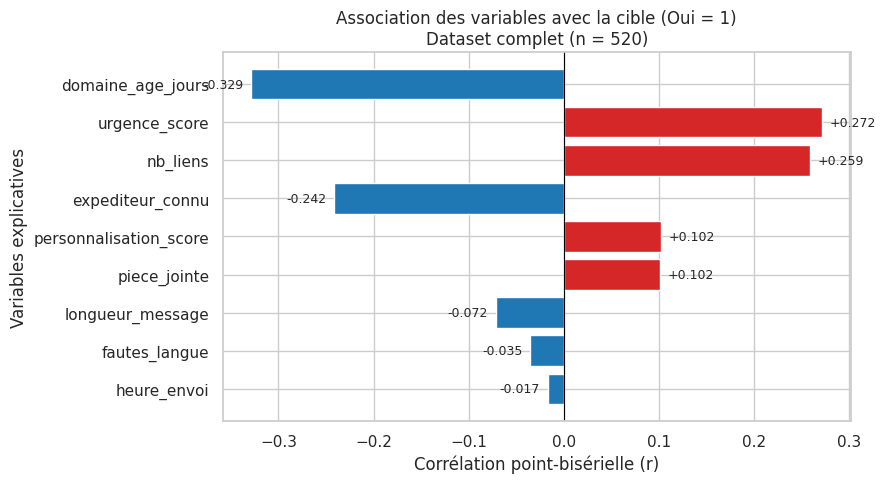

In [19]:
# Graphique : association de chaque variable avec la cible
# Dataset complet — Oui = 1

features = [
    'heure_envoi',
    'longueur_message',
    'nb_liens',
    'urgence_score',
    'domaine_age_jours',
    'fautes_langue',
    'expediteur_connu',
    'piece_jointe',
    'personnalisation_score'
]

# Encodage temporaire de la cible
y = df[TARGET].map({'Non': 0, 'Oui': 1})

# Calcul des corrélations point-bisérielles
association = (
    df[features]
    .corrwith(y, method='pearson')
    .rename("correlation_avec_Oui")
    .sort_values(key=abs, ascending=False)
    .to_frame()
)

display(association.round(3))

# Visualisation
fig, ax = plt.subplots(figsize=(9, 5))

vals = association["correlation_avec_Oui"][::-1]

colors = [
    "#d62728" if v > 0 else "#1f77b4"
    for v in vals
]

ax.barh(vals.index, vals.values, color=colors)

for i, v in enumerate(vals.values):
    ax.text(
        v + (0.008 if v >= 0 else -0.008),
        i,
        f"{v:+.3f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=9
    )

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Association des variables avec la cible (Oui = 1)\n"
    f"Dataset complet (n = {len(df)})"
)

ax.set_xlabel("Corrélation point-bisérielle (r)")
ax.set_ylabel("Variables explicatives")

plt.tight_layout()
plt.show()


## Graphique 2 — Association des variables avec la cible (Oui = 1)

| Rang | Variable | Corrélation | Interprétation |
|---:|---|---:|---|
| 1 | `domaine_age_jours` | -0.329 | Les domaines récents sont davantage associés aux messages malveillants. |
| 2 | `urgence_score` | +0.272 | Les messages malveillants présentent davantage de signaux d'urgence. |
| 3 | `nb_liens` | +0.259 | Les messages malveillants sont associés à davantage de liens. |
| 4 | `expediteur_connu` | -0.242 | Un expéditeur connu est davantage associé aux messages légitimes. |
| 5 | `personnalisation_score` | +0.102 | Une personnalisation élevée est légèrement associée aux messages malveillants. |
| 6 | `piece_jointe` | +0.102 | La présence d'une pièce jointe présente une association positive faible. |
| 7 | `longueur_message` | -0.072 | Faible association négative. |
| 8 | `fautes_langue` | -0.035 | Association presque nulle. |
| 9 | `heure_envoi` | -0.017 | Association presque nulle. |

### Interprétation des couleurs

- 🔴 Rouge : association positive avec `Oui` (message malveillant).
- 🔵 Bleu : association négative avec `Oui` (message malveillant).
- Une corrélation proche de zéro indique une faible association linéaire.

### Conclusion du graphique 2

- `domaine_age_jours` présente l'association la plus forte avec la cible.
- `urgence_score` et `nb_liens` constituent également des signaux intéressants.
- `expediteur_connu` apporte un signal important associé aux messages légitimes.
- `personnalisation_score` et `piece_jointe` présentent des associations positives faibles.
- `heure_envoi` et `fautes_langue` présentent des associations presque nulles.

### Remarque méthodologique

- Ces corrélations mesurent des associations et non une causalité.
- Une faible corrélation ne signifie pas qu'une variable est inutile pour la prédiction.
- Il est préférable de conserver les neuf variables explicatives au départ, puis d'évaluer leur utilité avec la validation croisée et les performances du modèle.

## 1. Tableau comparatif des indicateurs selon la cible

In [20]:
# Tableau comparatif des indicateurs selon la cible

comparaison = df.groupby(TARGET)[features].agg(
    ['mean', 'median', 'std']
).round(2)

display(comparaison)

heure_envoi              longueur_message                 \
                           mean median   std             mean median     std   
message_malveillant                                                            
Non                       12.29   12.0  6.77           420.65  431.0  160.18   
Oui                       12.03   13.0  7.18           394.66  398.0  169.86   

                    nb_liens              urgence_score               \
                        mean median   std          mean median   std   
message_malveillant                                                    
Non                     1.20    1.0  1.09          4.11    4.0  2.30   
Oui                     1.86    2.0  1.19          5.54    6.0  2.26   

                    domaine_age_jours                fautes_langue         \
                                 mean median     std          mean median   
message_malveillant                                                         
Non                            897.38  649.0  819.70          2.05    2.0   
Oui                            338.54  221.0  368.78          1.95    2.0   

                          expediteur_connu              piece_jointe         \
                      std             mean median   std         mean median   
message_malveillant                                                           
Non                  1.39             0.51    1.0  0.50         0.21    0.0   
Oui                  1.38             0.25    0.0  0.43         0.30    0.0   

                          personnalisation_score               
                      std                   mean median   std  
message_malveillant                                            
Non                  0.40                   4.82    5.0  2.53  
Oui                  0.46                   5.40    5.0  2.58

## 10. Construction de `X` et `y`

- `y` contient uniquement la variable cible.
- `X` contient les variables explicatives.
- Les colonnes de date et de semaine sont exclues : sans justification métier, elles feraient apprendre le calendrier plutôt que le phénomène.
- La cible est explicitement retirée de `X` pour éviter la fuite de données.


In [21]:
# Séparation des variables explicatives (X) et de la cible (y)

TARGET = 'message_malveillant'

# Les 9 variables explicatives conservées
features = [
    'heure_envoi',
    'longueur_message',
    'nb_liens',
    'urgence_score',
    'domaine_age_jours',
    'fautes_langue',
    'expediteur_connu',
    'piece_jointe',
    'personnalisation_score'
]

# Vérification des colonnes nécessaires
colonnes_manquantes = [
    col for col in features + [TARGET, 'date']
    if col not in df.columns
]

if colonnes_manquantes:
    raise ValueError(f"Colonnes absentes : {colonnes_manquantes}")

# Construction de X et y
X = df[features].copy()
y = df[TARGET].copy()

print("Variables explicatives (X) :", X.columns.tolist())
print("Nombre de features :", X.shape[1])
print("Variable cible (y) :", TARGET)
print("Dimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Variables explicatives (X) : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']
Nombre de features : 9
Variable cible (y) : message_malveillant
Dimensions de X : (520, 9)
Dimensions de y : (520,)


## 11. Séparation train / test

La séparation a déjà été définie au §8 pour permettre une EDA sans fuite. On la matérialise ici en `X_train` / `X_test` : **les mêmes indices** sont réutilisés, ce qu'un `assert` vérifie. `stratify=y` conserve la proportion de chaque classe.

Le test ne sera pas utilisé pour ajuster les transformations, choisir un modèle ni régler le seuil.


In [22]:
# Séparation des données en ensembles Train et Test

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Vérification des dimensions
print("Dimensions des ensembles :")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

# Vérification de l'absence de chevauchement
assert set(X_train.index).isdisjoint(set(X_test.index))

# Vérification de la répartition des classes
print("\nRépartition des classes — Train")
display(pd.DataFrame({
    "Effectif": y_train.value_counts().reindex(ORDER, fill_value=0),
    "Pourcentage (%)": (
        y_train.value_counts(normalize=True)
        .reindex(ORDER, fill_value=0) * 100
    ).round(2)
}))

print("\nRépartition des classes — Test")
display(pd.DataFrame({
    "Effectif": y_test.value_counts().reindex(ORDER, fill_value=0),
    "Pourcentage (%)": (
        y_test.value_counts(normalize=True)
        .reindex(ORDER, fill_value=0) * 100
    ).round(2)
}))

Dimensions des ensembles :
X_train : (416, 9)
X_test  : (104, 9)
y_train : (416,)
y_test  : (104,)

Répartition des classes — Train


,Effectif,Pourcentage (%)
message_malveillant,,
Non,299,71.88
Oui,117,28.12



Répartition des classes — Test


,Effectif,Pourcentage (%)
message_malveillant,,
Non,75,72.12
Oui,29,27.88


### Conclusion de la séparation Train/Test

Le dataset, composé de 520 messages et de 9 variables explicatives, a été divisé en deux ensembles :

- **Train (80 %) :** 416 messages, dont 299 légitimes et 117 malveillants.
- **Test (20 %) :** 104 messages, dont 75 légitimes et 29 malveillants.

La stratification (`stratify=y`) a permis de conserver une répartition similaire des deux classes dans les ensembles d'entraînement et de test.

Le jeu de test sera conservé pour l'évaluation finale des modèles afin d'éviter toute fuite d'information.

## Construire le pipeline d'imputation et de standardisation

- Variables numériques : imputation par la médiane puis standardisation.
- Variables catégorielles : imputation par la modalité la plus fréquente puis one-hot encoding.
- `handle_unknown="ignore"` traite une catégorie inconnue rencontrée plus tard.

Les transformations sont intégrées aux pipelines : elles sont ajustées **uniquement sur l'entraînement de chaque pli**, jamais sur le test.


In [23]:
#Définir les variables numériques
features_num = features.copy()

print("Variables numériques :", features_num)
print("Nombre de variables :", len(features_num))

Variables numériques : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']
Nombre de variables : 9


### SimpleImputer(strategy="median")	Remplace les valeurs manquantes par la médiane de chaque variable.
### StandardScaler()	Standardise les variables pour les mettre sur une échelle comparable.
### Pipeline	Enchaîne automatiquement les deux opérations.
### ColumnTransformer	Applique le traitement aux variables sélectionnées.

In [24]:
# Prétraitement des variables numériques
pipeline_num = Pipeline(steps=[
    ("imputation", SimpleImputer(strategy="median")),
    ("standardisation", StandardScaler())
])

preprocesseur = ColumnTransformer(
    transformers=[
        ("numerique", pipeline_num, features_num)
    ],
    remainder="drop"
)

print("Préprocesseur prêt.")
display(preprocesseur)

Préprocesseur prêt.


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerique', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feat

## 13. Processus Machine Learning du projet

Schéma identique à celui de l'application Streamlit. Le jeu de test n'est consulté qu'à l'étape 8, après la sélection du modèle et du seuil sur le train : aucune fuite de données, pas de one-hot encoding (les 9 variables explicatives sont numériques).


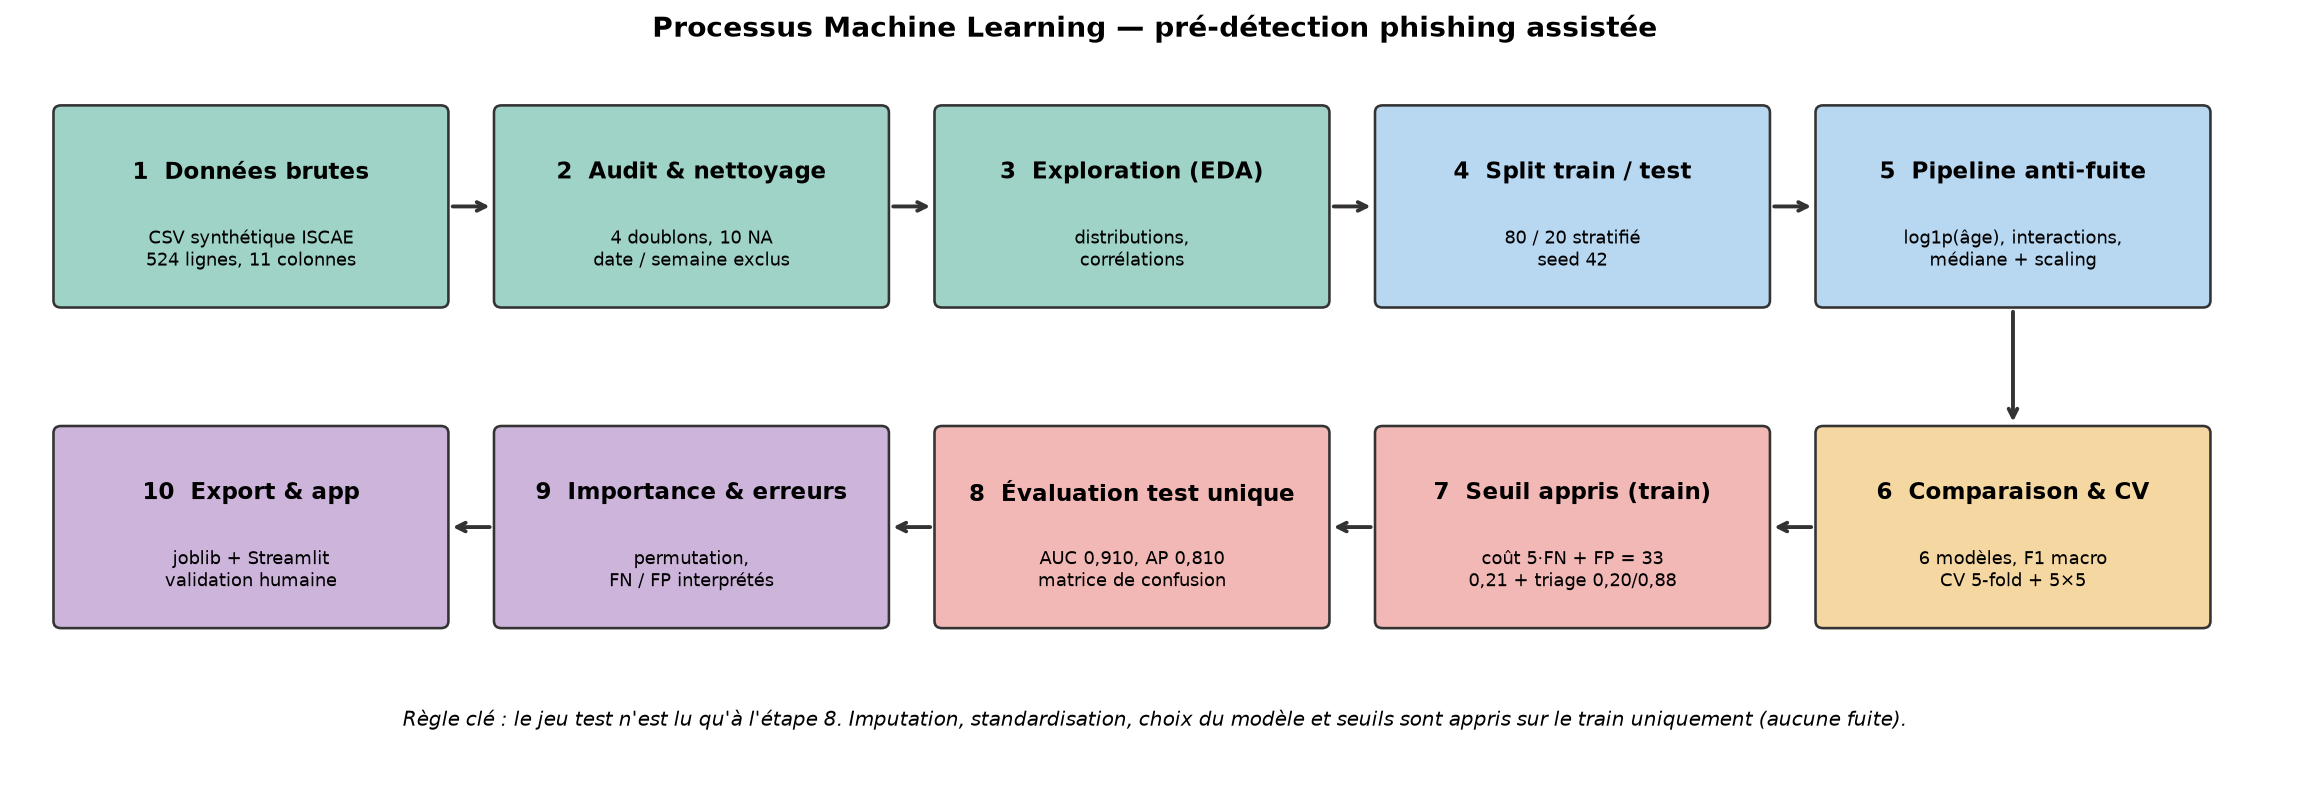

Règle clé : imputation, standardisation, modèle et seuils appris sur le train seul.


In [25]:
from IPython.display import Image as IPyImage, display
display(IPyImage(filename="artefacts/processus_phishing_ia.png"))
print("Règle clé : imputation, standardisation, modèle et seuils appris sur le train seul.")

## 14. Modèles candidats

On écarte la baseline majoritaire : elle prédit toujours `Non`, affiche ~72 % d'accuracy mais **ne détecte aucun phishing**. Elle sert seulement de repère pédagogique au §18.1.

Trois hypothèses complémentaires sont comparées :
1. **Régression logistique** : frontière linéaire, simple et interprétable.
2. **Random Forest** : ensemble d'arbres, capte les interactions non linéaires.
3. **SVM noyau RBF** : séparation à marge maximale, efficace sur un petit jeu numérique propre et stable en validation croisée ; `probability=True` fournit les probabilités.

Les modèles et prétraitements sont réunis dans des pipelines identiques.


In [26]:

# Définition des modèles
modeles = {
    "Regression_logistique": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random_Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight="balanced",
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "SVM_RBF": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=RANDOM_STATE
    )
}

# Intégration du prétraitement dans chaque pipeline
pipelines = {
    nom: Pipeline(steps=[
        ("pretraitement", clone(preprocesseur)),
        ("modele", modele)
    ])
    for nom, modele in modeles.items()
}

print("Modèles préparés :")
for nom, pipeline in pipelines.items():
    print(f"- {nom} : {pipeline}")


Modèles préparés :
- Regression_logistique : Pipeline(steps=[('pretraitement',
                 ColumnTransformer(transformers=[('numerique',
                                                  Pipeline(steps=[('imputation',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardisation',
                                                                   StandardScaler())]),
                                                  ['heure_envoi',
                                                   'longueur_message',
                                                   'nb_liens', 'urgence_score',
                                                   'domaine_age_jours',
                                                   'fautes_langue',
                                                   'expediteur_connu',
                                                   'piece_jointe',
      

## validation croisée stratifiée

In [27]:
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

# Validation croisée stratifiée
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

def _oui(y_true, y_score):
    s = np.asarray(y_score)
    return s[:, 1] if s.ndim == 2 else s

def auc_oui(y_true, y_score):
    return roc_auc_score((y_true == "Oui").astype(int), _oui(y_true, y_score))

def ap_oui(y_true, y_score):
    return average_precision_score((y_true == "Oui").astype(int), _oui(y_true, y_score))

# Métriques : la classe positive est "Oui", pas la valeur 1 par défaut.
# sklearn 1.8 n'accepte plus pos_label dans les scorer de classement : on passe
# par de petites fonctions qui codent "Oui" en 1.
scoring = {
    "precision": make_scorer(precision_score, pos_label="Oui", zero_division=0),
    "recall": make_scorer(recall_score, pos_label="Oui", zero_division=0),
    "f1": make_scorer(f1_score, pos_label="Oui", zero_division=0),
    "roc_auc": make_scorer(auc_oui, response_method="predict_proba"),
    "average_precision": make_scorer(ap_oui, response_method="predict_proba")
}

print("Validation croisée prête.")
print("Nombre de folds :", cv.get_n_splits(X_train, y_train))
print("Classe positive :", "Oui")


Validation croisée prête.
Nombre de folds : 5
Classe positive : Oui


## Exécuter la validation croisée sur les trois modèles

In [28]:

resultats_cv = []

for nom, pipeline in pipelines.items():

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1,
        error_score="raise"
    )

    resultats_cv.append({
        "Modele": nom,

        "Precision_moyenne": scores["test_precision"].mean(),
        "Precision_std": scores["test_precision"].std(),

        "Recall_moyen": scores["test_recall"].mean(),
        "Recall_std": scores["test_recall"].std(),

        "F1_moyen": scores["test_f1"].mean(),
        "F1_std": scores["test_f1"].std(),

        "ROC_AUC_moyen": scores["test_roc_auc"].mean(),
        "ROC_AUC_std": scores["test_roc_auc"].std(),

        "AP_moyenne": scores["test_average_precision"].mean(),
        "AP_std": scores["test_average_precision"].std()
    })

resultats_cv_df = pd.DataFrame(resultats_cv)

display(resultats_cv_df.round(3))


,Modele,Precision_moyenne,Precision_std,Recall_moyen,Recall_std,F1_moyen,F1_std,ROC_AUC_moyen,ROC_AUC_std,AP_moyenne,AP_std
0,Regression_logistique,0.624,0.081,0.830,0.102,0.712,0.089,0.899,0.047,0.795,0.073
1,Random_Forest,0.754,0.083,0.641,0.079,0.691,0.075,0.900,0.032,0.809,0.056
2,SVM_RBF,0.642,0.026,0.778,0.039,0.703,0.022,0.888,0.028,0.762,0.049


# Comparaison des modèles — Validation croisée

## 1. Comparaison des résultats

| Modèle | Precision | Recall | F1-score | ROC-AUC | AP |
|---|---:|---:|---:|---:|---:|
| Régression logistique | 0.624 | **0.830** | **0.712** | 0.899 | 0.795 |
| Random Forest | **0.754** | 0.641 | 0.691 | **0.900** | **0.809** |
| SVM RBF | 0.642 | 0.778 | 0.703 | 0.888 | 0.762 |

## 2. Interprétation de chaque modèle

### 2.1. Régression logistique

- **Recall = 0.830 :** détecte environ 83 % des messages malveillants.
- **Precision = 0.624 :** environ 62,4 % des alertes sont réellement malveillantes.
- **F1-score = 0.712 :** meilleur F1-score des trois modèles.

**Interprétation :** elle détecte le plus grand nombre de messages malveillants, mais génère davantage de fausses alertes.

### 2.2. Random Forest

- **Recall = 0.641 :** détecte environ 64,1 % des messages malveillants.
- **Precision = 0.754 :** les alertes sont plus fiables.
- **ROC-AUC = 0.900 et AP = 0.809 :** meilleures valeurs de discrimination et de classement.

**Interprétation :** elle produit des alertes plus précises, mais laisse passer davantage de messages malveillants.

### 2.3. SVM RBF

- **Recall = 0.778 :** détecte environ 77,8 % des messages malveillants.
- **Precision = 0.642 :** environ 64,2 % des alertes sont réellement malveillantes.
- **F1-score = 0.703 :** deuxième meilleur compromis entre Precision et Recall.

**Interprétation :** il présente un compromis intermédiaire, mais n'obtient pas la meilleure performance globale sur les métriques observées.

## 3. Synthèse comparative

- **Régression logistique :** meilleure capacité de détection des messages malveillants (Recall = 0.830) et meilleur F1-score (0.712).
- **Random Forest :** meilleure fiabilité des alertes (Precision = 0.754), meilleur ROC-AUC (0.900) et meilleure Average Precision (0.809).
- **SVM RBF :** performances intermédiaires, sans être premier sur les métriques étudiées.

## 4. Conclusion provisoire

Compte tenu de l'objectif du projet, qui consiste à détecter les messages malveillants et à limiter les faux négatifs, la **régression logistique est retenue provisoirement comme modèle candidat principal**.

Cependant, Random Forest reste une alternative intéressante grâce à sa meilleure Precision et à ses scores ROC-AUC et AP.

Une analyse complémentaire des seuils de décision permettra de rechercher un meilleur équilibre entre la détection des messages malveillants et la limitation des fausses alertes.

*Remarque : les résultats correspondent aux moyennes obtenues lors d'une validation croisée stratifiée à 5 folds sur les données d'entraînement. Ils ne représentent pas encore les performances finales sur le jeu de test.*

## Visualiser la comparaison des modèles

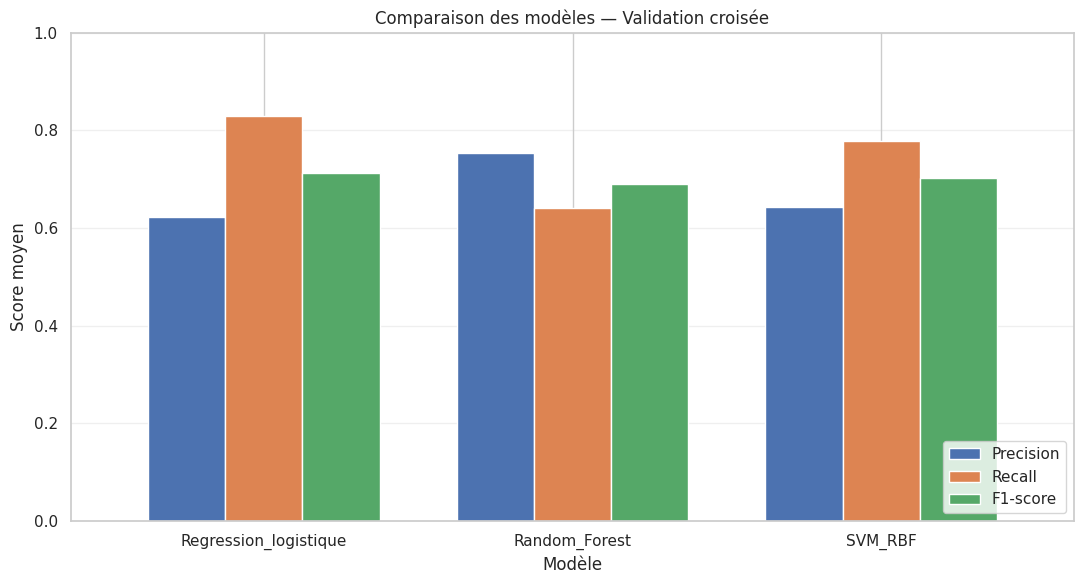

In [29]:

metriques = [
    "Precision_moyenne",
    "Recall_moyen",
    "F1_moyen"
]

resultats_visu = resultats_cv_df.set_index("Modele")[metriques]

ax = resultats_visu.plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("Comparaison des modèles — Validation croisée")
plt.ylabel("Score moyen")
plt.xlabel("Modèle")
plt.xticks(rotation=0)
plt.legend(
    ["Precision", "Recall", "F1-score"],
    loc="lower right"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## matrice de confusion OOF des trois modèles

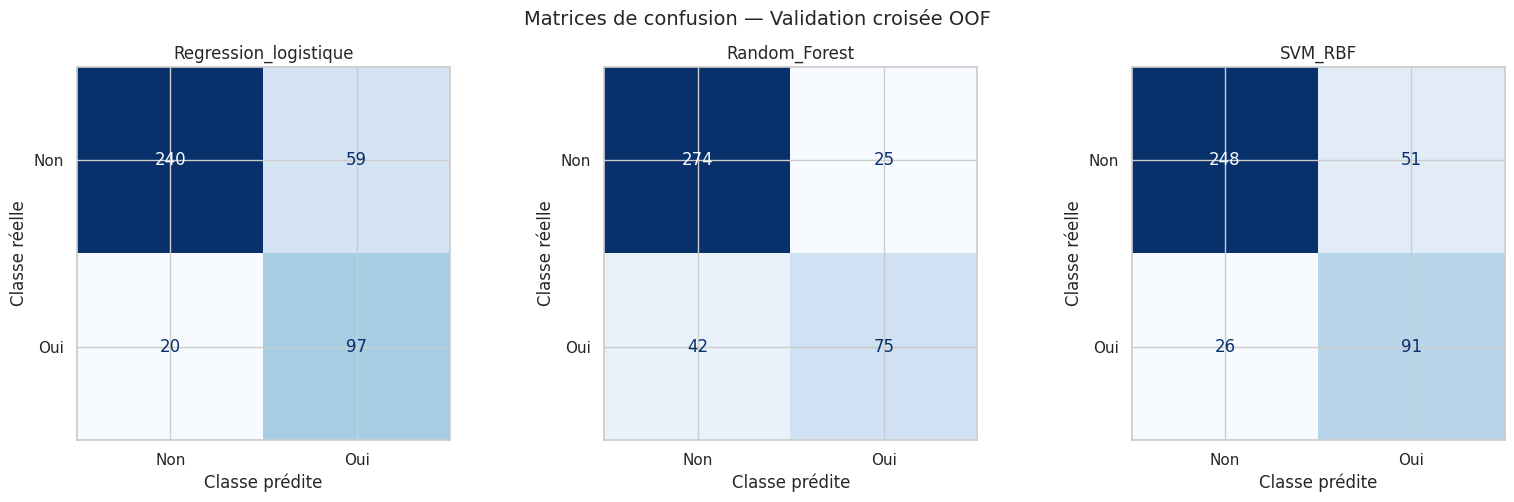

In [30]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Ordre des classes
labels = ["Non", "Oui"]

# Calcul des prédictions hors-fold pour chaque modèle
predictions_oof = {}

for nom, pipeline in pipelines.items():

    y_pred_oof = cross_val_predict(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv,
        method="predict",
        n_jobs=-1
    )

    predictions_oof[nom] = y_pred_oof

# Affichage des matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (nom, y_pred) in zip(axes, predictions_oof.items()):

    cm = confusion_matrix(
        y_train,
        y_pred,
        labels=labels
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(nom)
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.suptitle(
    "Matrices de confusion — Validation croisée OOF",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [31]:

resultats_cm = []

for nom, y_pred in predictions_oof.items():

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        y_pred,
        labels=["Non", "Oui"]
    ).ravel()

    resultats_cm.append({
        "Modele": nom,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

df_cm = pd.DataFrame(resultats_cm)

display(df_cm)


,Modele,TN,FP,FN,TP
0,Regression_logistique,240,59,20,97
1,Random_Forest,274,25,42,75
2,SVM_RBF,248,51,26,91


## Calculer les probabilités OOF de la régression logistique

In [32]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Récupérer les probabilités OOF de la régression logistique
probas_oof = cross_val_predict(
    pipelines["Regression_logistique"],
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Identifier la colonne correspondant à la classe Oui
classes = np.unique(y_train)
index_oui = list(classes).index("Oui")

y_proba_oui = probas_oof[:, index_oui]

print("Probabilités OOF calculées.")
print("Classe positive :", classes[index_oui])


Probabilités OOF calculées.
Classe positive : Oui


## Tester plusieurs seuils

In [33]:

seuils = np.arange(0.10, 0.81, 0.05)

resultats_seuils = []

for seuil in seuils:

    # Prédictions selon le seuil choisi
    y_pred_seuil = np.where(
        y_proba_oui >= seuil,
        "Oui",
        "Non"
    )

    # Métriques
    precision = precision_score(
        y_train, y_pred_seuil,
        pos_label="Oui",
        zero_division=0
    )

    recall = recall_score(
        y_train, y_pred_seuil,
        pos_label="Oui",
        zero_division=0
    )

    f1 = f1_score(
        y_train, y_pred_seuil,
        pos_label="Oui",
        zero_division=0
    )

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        y_pred_seuil,
        labels=["Non", "Oui"]
    ).ravel()

    resultats_seuils.append({
        "Seuil": round(seuil, 2),
        "Precision": precision,
        "Recall": recall,
        "F1_score": f1,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    })

df_seuils = pd.DataFrame(resultats_seuils)

display(df_seuils.round(3))


,Seuil,Precision,Recall,F1_score,TN,FP,FN,TP
0,0.10,0.390,0.974,0.557,121,178,3,114
1,0.15,0.427,0.974,0.594,146,153,3,114
2,0.20,0.452,0.957,0.614,163,136,5,112
3,0.25,0.483,0.949,0.640,180,119,6,111
4,0.30,0.509,0.923,0.657,195,104,9,108
5,0.35,0.541,0.906,0.677,209,90,11,106
6,0.40,0.582,0.880,0.701,225,74,14,103
7,0.45,0.607,0.846,0.707,235,64,18,99
8,0.50,0.622,0.829,0.711,240,59,20,97
9,0.55,0.669,0.795,0.727,253,46,24,93


## Visualiser l'effet du seuil

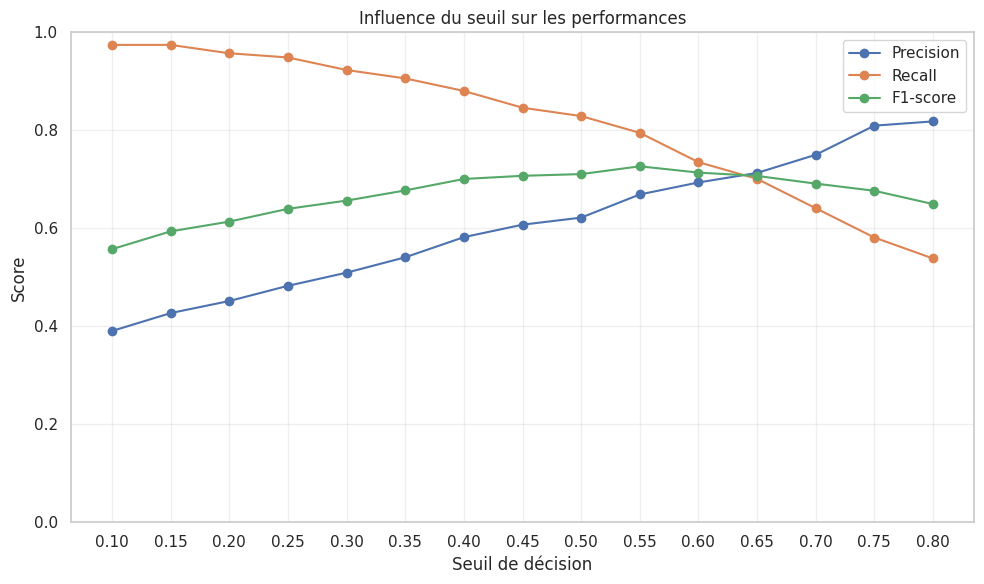

In [34]:

plt.figure(figsize=(10, 6))

plt.plot(
    df_seuils["Seuil"],
    df_seuils["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    df_seuils["Seuil"],
    df_seuils["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    df_seuils["Seuil"],
    df_seuils["F1_score"],
    marker="o",
    label="F1-score"
)

plt.xlabel("Seuil de décision")
plt.ylabel("Score")
plt.title("Influence du seuil sur les performances")
plt.xticks(seuils.round(2))
plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Choisir le seuil optimal

In [35]:

meilleur_resultat = df_seuils.loc[
    df_seuils["F1_score"].idxmax()
]

meilleur_seuil = meilleur_resultat["Seuil"]

print("Meilleur seuil selon le F1-score :", meilleur_seuil)
display(meilleur_resultat.to_frame("Valeur"))


Meilleur seuil selon le F1-score : 0.55


,Valeur
Seuil,0.550000
Precision,0.669065
Recall,0.794872
F1_score,0.726562
TN,253.000000
FP,46.000000
FN,24.000000
TP,93.000000


## examiner les seuils qui atteignent un Recall d'au moins 0.90 :

In [36]:

candidats = df_seuils[
    df_seuils["Recall"] >= 0.90
].sort_values(
    "Precision",
    ascending=False
)

print("Seuils avec Recall >= 0.90 :")
display(candidats.round(3))


Seuils avec Recall >= 0.90 :


,Seuil,Precision,Recall,F1_score,TN,FP,FN,TP
5,0.35,0.541,0.906,0.677,209,90,11,106
4,0.30,0.509,0.923,0.657,195,104,9,108
3,0.25,0.483,0.949,0.640,180,119,6,111
2,0.20,0.452,0.957,0.614,163,136,5,112
1,0.15,0.427,0.974,0.594,146,153,3,114
0,0.10,0.390,0.974,0.557,121,178,3,114


## évaluation finale sur X_test

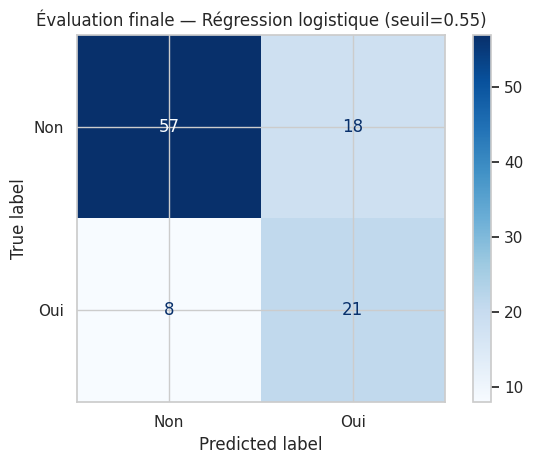

Precision : 0.5384615384615384
Recall : 0.7241379310344828
F1-score : 0.6176470588235294
ROC-AUC : 0.8321839080459771
Average Precision : 0.6559380391774674


In [37]:
# 1. Définir le seuil final
SEUIL_FINAL = 0.55

# 2. Entraîner le modèle sur X_train uniquement
modele_final = clone(pipelines["Regression_logistique"])
modele_final.fit(X_train, y_train)

# 3. Calculer les probabilités sur X_test
proba_test = modele_final.predict_proba(X_test)

idx_oui = list(modele_final.classes_).index("Oui")
y_proba_test_oui = proba_test[:, idx_oui]

# 4. Appliquer le seuil choisi
y_pred_test = np.where(
    y_proba_test_oui >= SEUIL_FINAL,
    "Oui",
    "Non"
)

# 5. Matrice de confusion
cm_test = confusion_matrix(
    y_test,
    y_pred_test,
    labels=["Non", "Oui"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Non", "Oui"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Évaluation finale — Régression logistique (seuil={SEUIL_FINAL})")
plt.tight_layout()
plt.show()

# 6. Métriques finales
print("Precision :", precision_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("Recall :", recall_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("F1-score :", f1_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("ROC-AUC :", roc_auc_score(
    (y_test == "Oui").astype(int),
    y_proba_test_oui
))

print("Average Precision :", average_precision_score(
    (y_test == "Oui").astype(int),
    y_proba_test_oui
))

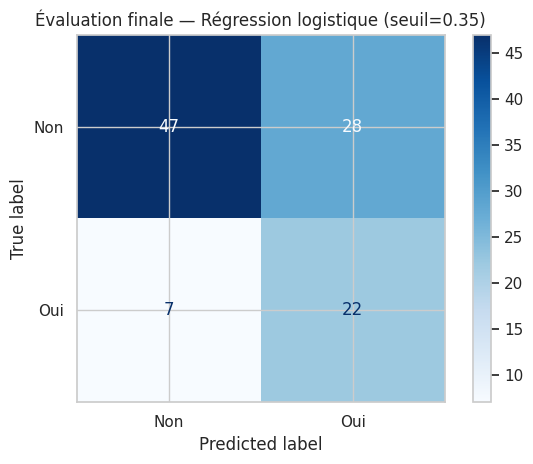

Precision : 0.44
Recall : 0.7586206896551724
F1-score : 0.5569620253164557
ROC-AUC : 0.8321839080459771
Average Precision : 0.6559380391774674


In [38]:
# 1. Définir le seuil final
SEUIL_FINAL = 0.35

# 2. Entraîner le modèle sur X_train uniquement
modele_final = clone(pipelines["Regression_logistique"])
modele_final.fit(X_train, y_train)

# 3. Calculer les probabilités sur X_test
proba_test = modele_final.predict_proba(X_test)

idx_oui = list(modele_final.classes_).index("Oui")
y_proba_test_oui = proba_test[:, idx_oui]

# 4. Appliquer le seuil choisi
y_pred_test = np.where(
    y_proba_test_oui >= SEUIL_FINAL,
    "Oui",
    "Non"
)

# 5. Matrice de confusion
cm_test = confusion_matrix(
    y_test,
    y_pred_test,
    labels=["Non", "Oui"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Non", "Oui"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title(f"Évaluation finale — Régression logistique (seuil={SEUIL_FINAL})")
plt.tight_layout()
plt.show()

# 6. Métriques finales
print("Precision :", precision_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("Recall :", recall_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("F1-score :", f1_score(
    y_test, y_pred_test, pos_label="Oui", zero_division=0
))

print("ROC-AUC :", roc_auc_score(
    (y_test == "Oui").astype(int),
    y_proba_test_oui
))

print("Average Precision :", average_precision_score(
    (y_test == "Oui").astype(int),
    y_proba_test_oui
))

## 15. Sélection du modèle sur le train — validation croisée 5-fold

C'est **ici** que se joue la sélection, avant toute lecture du test. Chaque pipeline est évalué par `StratifiedKFold(5)` sur les 416 messages du train : moyennes et écarts-types portent sur 5 scores de pli.

**Protocole exact** : 5 plis stratifiés, `shuffle=True`, `random_state=42`, soit **5 entraînements par modèle**. Il ne faut pas le confondre avec la CV **5×5 répétée** du §17 (25 entraînements, seeds 42–46), qui sert à apprendre le seuil et à mesurer la stabilité : les deux jeux de valeurs ne sont pas comparables.


In [39]:
min_classe_train = y_train.value_counts().min()
n_splits = min(5, int(min_classe_train))

if n_splits >= 2:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scoring = {
        "accuracy": "accuracy",
        "precision_macro": "precision_macro",
        "recall_macro": "recall_macro",
        "f1_macro": "f1_macro"
    }
    cv_rows = []
    for nom, pipeline in pipelines.items():
        cv_scores = cross_validate(
            pipeline, X_train, y_train,
            cv=cv, scoring=scoring, n_jobs=-1
        )
        cv_rows.append({
            "Modele": nom,
            "Accuracy_CV_moyenne": cv_scores["test_accuracy"].mean(),
            "F1_macro_CV_moyenne": cv_scores["test_f1_macro"].mean(),
            "F1_macro_CV_ecart_type": cv_scores["test_f1_macro"].std()
        })
    cv_resultats = pd.DataFrame(cv_rows).sort_values("F1_macro_CV_moyenne", ascending=False)
    print("Protocole : CV 5-fold simple (5 entraînements par modèle, seed 42) — train seul")
    print("À ne pas confondre avec la CV 5x5 répétée du §17 (25 entraînements) : valeurs non comparables.")
    display(cv_resultats.round(3))
else:
    print("Validation croisée stratifiée impossible : effectif insuffisant dans une classe.")

Protocole : CV 5-fold simple (5 entraînements par modèle, seed 42) — train seul
À ne pas confondre avec la CV 5x5 répétée du §17 (25 entraînements) : valeurs non comparables.


,Modele,Accuracy_CV_moyenne,F1_macro_CV_moyenne,F1_macro_CV_ecart_type
1,Random_Forest,0.839,0.791,0.051
0,Regression_logistique,0.810,0.785,0.067
2,SVM_RBF,0.815,0.784,0.018


## 16. Comparaison descriptive des trois modèles de référence sur le test (a posteriori)

⚠️ **Lis cette section comme un constat, pas comme une sélection.** Le modèle et le seuil ont été choisis **avant**, sur le train seul : validation croisée au §15, puis protocole du §17. Les trois modèles ci-dessous sont entraînés sur le train et évalués une fois sur le test, pour **documenter** leur comportement au seuil par défaut 0,50. Aucun choix du notebook ne repose sur ce tableau.

Cette lecture unique du test est assumée : elle ne sert qu'à la comparaison descriptive et à l'illustration pédagogique ; le chiffre de performance du modèle déployé est produit au §17–§18, avec le seuil appris sur le train.


In [40]:
import numpy as np
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, mean_absolute_error,
                             roc_auc_score, average_precision_score,
                             mean_squared_error, r2_score)

resultats = []
probabilites = {}
predictions = {}

# Conversion Oui/Non -> 1/0
y_test_num = (y_test == "Oui").astype(int)

for nom, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    predictions[nom] = y_pred

    y_pred_num = (pd.Series(y_pred) == "Oui").astype(int).values

    # Probabilité de la classe "Oui"
    idx_oui = list(pipeline.classes_).index("Oui")
    y_proba = pipeline.predict_proba(X_test)[:, idx_oui]
    probabilites[nom] = y_proba

    resultats.append({
        "Modele": nom,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_macro": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "AUC": roc_auc_score(y_test_num, y_proba),
        "Average_precision": average_precision_score(y_test_num, y_proba),
        # Sur les classes prédites
        "MAE": mean_absolute_error(y_test_num, y_pred_num),
        "RMSE": np.sqrt(mean_squared_error(y_test_num, y_pred_num)),
        "R2": r2_score(y_test_num, y_pred_num),
        # Sur les probabilités
        "MAE_proba": mean_absolute_error(y_test_num, y_proba),
        "RMSE_proba": np.sqrt(mean_squared_error(y_test_num, y_proba)),
        "R2_proba": r2_score(y_test_num, y_proba),
    })

    print(f"Entraînement terminé : {nom}")

resultats_df = pd.DataFrame(resultats).sort_values("F1_macro", ascending=False)
display(resultats_df.round(3))

Entraînement terminé : Regression_logistique


Entraînement terminé : Random_Forest
Entraînement terminé : SVM_RBF


,Modele,Accuracy,Precision_macro,Recall_macro,F1_macro,AUC,Average_precision,MAE,RMSE,R2,MAE_proba,RMSE_proba,R2_proba
1,Random_Forest,0.798,0.752,0.723,0.734,0.866,0.698,0.202,0.449,-0.004,0.288,0.365,0.337
0,Regression_logistique,0.721,0.692,0.733,0.694,0.832,0.656,0.279,0.528,-0.387,0.298,0.417,0.134
2,SVM_RBF,0.721,0.692,0.733,0.694,0.834,0.633,0.279,0.528,-0.387,0.286,0.386,0.259


## 17. Modèle retenu : `log_age`, interactions et seuil appris sur le train

Les limitations mesurées sur le modèle de référence sont corrigées ici :

1. **`domaine_age_jours` est transformé** : la variable va de 1 à 5 874 jours et sa distribution est très asymétrique. On utilise `log1p(domaine_age_jours)` **à l'intérieur du pipeline**, donc sans fuite.
2. **Les variables de bruit sont retirées** : `heure_envoi`, `longueur_message` et `fautes_langue` ont une importance par permutation faible sur le train (≤ 0,05, contre 0,24 pour `domaine_age_jours`).
3. **Deux interactions métier** sont ajoutées : `urgence × expéditeur inconnu` et `nb_liens × expéditeur inconnu`.
4. **Modèle** : régression logistique pondérée (`class_weight="balanced"`), plus interprétable que le RF.
5. **Seuil appris sur le train seul**, par validation croisée **StratifiedKFold 5×5 répétée** (25 entraînements) :
   - coût `C = c_FN·FN + c_FP·FP` avec `c_FN = 5`, `c_FP = 1` → plateau quasi minimal **0,20–0,22**, médiane **0,21** = seuil binaire retenu ;
   - sensibilité publiée : `c_FN = 3` → 0,47 ; `c_FN = 10` → 0,20 ; le rapport de coût doit être validé par le RSSI ;
   - **triage 3 zones** : `P(Oui) < 0,20` → 🟢 Normal, `0,20 ≤ P(Oui) < 0,88` → 🟠 revue humaine, `P(Oui) ≥ 0,88` → 🔴 Alerte. Les cas ambigus ne sont pas « classés » : ils sont confiés à l'analyste ;
   - **incertitude** : IC95 % bootstrap (2 000 tirages sur le test) pour le rappel, la précision et le taux de fausses alertes.

Le pipeline reçoit les **colonnes brutes** de `X` (celles du formulaire Streamlit) et fait la transformation en interne : l'application et le notebook utilisent exactement le même code. Le test n'est utilisé qu'**une seule fois**, à la fin, pour mesurer — jamais pour choisir modèle ou seuil.


### 17.1 OOF, matrice de validation croisée et protocoles

**OOF** = *Out-Of-Fold* (« hors pli »). Avec `StratifiedKFold(5)` répété 5 fois, on entraîne 25 modèles ; chaque modèle prédit uniquement les lignes qu'il n'a jamais vues. On moyenne ces probabilités pour obtenir **une probabilité OOF par ligne du train**. La matrice de confusion qui en découle porte donc sur les **416 lignes du train**, pas sur les 104 du test.

**Deux protocoles différents coexistent dans ce notebook — ils ne sont pas comparables :**

| Protocole | Où | Usage | Ce qu'il produit |
|---|---|---|---|
| **CV 5-fold simple**, seed 42, 5 entraînements | §15 | Choisir le modèle de référence | F1 macro moyen par fold : RF 0,791 ± 0,051 ; LR 0,785 ± 0,067 ; SVM 0,784 ± 0,018 |
| **CV 5×5 répétée**, seeds 42–46, 25 entraînements | §17 | Apprendre le seuil et mesurer la stabilité | AUC 0,909 ± 0,003 ; AP 0,812 ± 0,003 ; F1 macro OOF au seuil 0,50 = **0,808** |

Le premier découpe une seule fois ; le second moyenne 5 découpages différents et agrège les probabilités. Un F1 de 0,791 (5-fold) et un F1 de 0,808 (OOF 5×5) ne mesurent donc pas la même chose : on ne les classe pas l'un contre l'autre.

Ici, les hyperparamètres sont fixés a priori (pas de recherche en grille) : la CV sert à la stabilité et au seuil, pas à une sélection d'hyperparamètres. Elle n'est donc pas imbriquée, et cette estimation reste légèrement optimiste — c'est une limite à connaître.

Au seuil retenu **0,21**, la matrice OOF du train est : **TN = 182 · FP = 117 · FN = 3 · TP = 114**. Le coût correspondant est `5·3 + 117 = 132` ; le coût minimal de 128 est atteint à 0,20 (`5·2 + 118 = 128`), d'où le plateau 0,20–0,22 et la médiane 0,21. On ne peut pas obtenir `FN = 0` et `FP = 0` simultanément : l'AUC de validation croisée vaut **0,909** (0,911 sur les probabilités moyennées), pas 1. Baisser le seuil réduit les FN mais augmente fortement les FP (à 0,20 : FN = 2, FP = 118). La matrice du test, au §18.4, est l'évaluation finale indépendante.


In [41]:
# =====================================================================
# AMÉLIORATION PHISHING — version simplifiée
# Pipeline sans fuite, CV 5x5 répétée, seuil par coût, triage 3 zones,
# bootstrap. Le test n'est lu qu'à la fin.
# =====================================================================
import json, joblib
from pathlib import Path
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             confusion_matrix, brier_score_loss)


class FeaturesPhishing(BaseEstimator, TransformerMixin):
    """Feature engineering sans fuite : `fit` n'apprend aucune statistique."""

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        out = pd.DataFrame(index=X.index)
        out["log_age"] = np.log1p(X["domaine_age_jours"])
        for c in ["urgence_score", "nb_liens", "expediteur_connu",
                  "piece_jointe", "personnalisation_score"]:
            out[c] = X[c]
        out["urg_x_inconnu"] = X["urgence_score"] * (1 - X["expediteur_connu"])
        out["liens_x_inconnu"] = X["nb_liens"] * (1 - X["expediteur_connu"])
        return out


def construire_modele():
    return Pipeline([
        ("features", FeaturesPhishing()),
        ("imputation", SimpleImputer(strategy="median")),
        ("standardisation", StandardScaler()),
        ("modele", LogisticRegression(max_iter=3000, class_weight="balanced",
                                      random_state=RANDOM_STATE)),
    ])


modele_ameliore = construire_modele()
COUT_FN, COUT_FP = 5, 1
SEUILS = np.round(np.arange(0.02, 0.99, 0.01), 2)
y_tr01 = (y_train == "Oui").astype(int).values
y_te01 = (y_test == "Oui").astype(int).values


def matrice(y_true, p, seuil):
    """TN, FP, FN, TP pour un seuil donné."""
    tn, fp, fn, tp = confusion_matrix(y_true, (p >= seuil).astype(int),
                                      labels=[0, 1]).ravel()
    return {"TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}


def cout(y_true, p, seuil, c_fn=COUT_FN):
    m = matrice(y_true, p, seuil)
    return c_fn * m["FN"] + COUT_FP * m["FP"]


def probas_validation(modele, X, y, n_repetitions=5):
    """Probabilités de validation croisée, moyennées sur n répétitions (CV 5-fold)."""
    idx_oui = sorted(y.unique().tolist()).index("Oui")
    repetitions, aucs, aps = [], [], []
    for seed in range(RANDOM_STATE, RANDOM_STATE + n_repetitions):
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
        p = cross_val_predict(modele, X, y, cv=cv,
                              method="predict_proba")[:, idx_oui]
        repetitions.append(p)
        aucs.append(roc_auc_score((y == "Oui").astype(int), p))
        aps.append(average_precision_score((y == "Oui").astype(int), p))
    return np.mean(repetitions, axis=0), np.array(aucs), np.array(aps)


def seuil_par_cout(y_true, p, c_fn=COUT_FN):
    """Médiane du plateau de coût quasi minimal (tolérance 5 %)."""
    couts = np.array([cout(y_true, p, t, c_fn) for t in SEUILS])
    best = float(couts.min())
    plateau = SEUILS[couts <= best * 1.05 + 1e-9]
    return float(np.median(plateau)), plateau, best, couts


def seuils_triage(y_true, p, seuil_opt):
    """Deux seuils appris sur le train : rappel en validation croisée >= 98 %, précision en validation croisée >= 85 %."""
    m = [matrice(y_true, p, t) for t in SEUILS]
    rappels = np.array([x["TP"] / max(x["TP"] + x["FN"], 1) for x in m])
    precisions = np.array([x["TP"] / max(x["TP"] + x["FP"], 1) for x in m])
    bas = SEUILS[rappels >= 0.98]
    haut = SEUILS[precisions >= 0.85]
    bas = float(max(bas[bas <= seuil_opt])) if (bas <= seuil_opt).any() else seuil_opt
    haut = float(min(haut[haut >= seuil_opt])) if (haut >= seuil_opt).any() else seuil_opt
    return (bas, haut) if bas <= haut else (seuil_opt, seuil_opt)


# --- 1. Stabilité du modèle : CV 5×5 répétée sur le train -------------------
p_cv, auc_cv, ap_cv = probas_validation(modele_ameliore, X_train, y_train)
print(f"CV 5x5 répétée — AUC en validation croisée {np.mean(auc_cv):.4f} ± {np.std(auc_cv):.4f} | "
      f"AP {np.mean(ap_cv):.4f} ± {np.std(ap_cv):.4f}")
print(f"Validation croisée (probabilités moyennées) — AUC {roc_auc_score(y_tr01, p_cv):.4f} | "
      f"AP {average_precision_score(y_tr01, p_cv):.4f}")

# --- 1 bis. Même protocole 5-fold que le §15, pour comparer le modèle retenu ---
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv5_f1 = cross_validate(modele_ameliore, X_train, y_train, cv=cv5,
                        scoring="f1_macro", n_jobs=-1)["test_score"]
print(f"CV 5-fold simple (même protocole que §15) — F1 macro {cv5_f1.mean():.4f} ± {cv5_f1.std():.4f}")

# Deux lectures souvent citées dans les markdowns : OOF 5×5 au seuil 0,50 et moyenne des 25 plis.
f1_oof_50 = f1_score(y_tr01, (p_cv >= 0.50).astype(int), average="macro")
f1_25_plis = []
for seed in range(RANDOM_STATE, RANDOM_STATE + 5):
    cv_s = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    f1_25_plis += list(cross_validate(modele_ameliore, X_train, y_train, cv=cv_s,
                                      scoring="f1_macro", n_jobs=-1)["test_score"])
f1_25_plis = np.array(f1_25_plis)
print(f"OOF 5×5 (probabilités moyennées) — F1 macro au seuil 0,50 {f1_oof_50:.4f}")
print(f"25 plis CV 5×5 — F1 macro moyen {f1_25_plis.mean():.4f} ± {f1_25_plis.std():.4f}")

# --- 2. Seuil binaire : plateau de coût minimal -----------------------------
SEUIL_OPT, plateau, cout_min, couts_cv = seuil_par_cout(y_tr01, p_cv)
print(f"Coût minimal en validation croisée {cout_min:.0f} à {SEUILS[int(np.argmin(couts_cv))]:.2f} ; "
      f"plateau {plateau.min():.2f}–{plateau.max():.2f} ; seuil retenu = {SEUIL_OPT:.2f}")
print("Sensibilité du coût :", end=" ")
for c_fn in (3, 5, 10):
    s, pl, _, _ = seuil_par_cout(y_tr01, p_cv, c_fn)
    print(f"c_FN={c_fn} → {s:.2f} ({pl.min():.2f}–{pl.max():.2f})", end=" ; ")
print()

# --- 2 bis. MATRICE DE CONFUSION OOF — validation croisée 5x5, train seul ----
m_cv = matrice(y_tr01, p_cv, SEUIL_OPT)
matrice_oof_cv = pd.DataFrame(
    [[m_cv["TN"], m_cv["FP"]], [m_cv["FN"], m_cv["TP"]]],
    index=["Réel : Non", "Réel : Oui"],
    columns=["Prédit : Non", "Prédit : Oui"],
)
print("Matrice de confusion OOF (validation croisée 5×5 sur le train) :")
display(matrice_oof_cv)
print(f"OOF — TN={m_cv['TN']} · FP={m_cv['FP']} · FN={m_cv['FN']} · TP={m_cv['TP']} "
      f"| n={len(y_tr01)} | coût 5·FN+FP={COUT_FN * m_cv['FN'] + COUT_FP * m_cv['FP']}")
print("À 0,20 : FN=2 / FP=118 ; à 0,22 : FN=4 / FP=114 — zéro FN et zéro FP simultanés est impossible ici (AUC OOF ≈ 0,911).")

# --- 3. Triage 3 zones (appris sur le train, jamais sur le test) ------------
SEUIL_BAS, SEUIL_HAUT = seuils_triage(y_tr01, p_cv, SEUIL_OPT)
print(f"Triage : Normal < {SEUIL_BAS:.2f} | revue humaine {SEUIL_BAS:.2f}–{SEUIL_HAUT:.2f} "
      f"| Alerte ≥ {SEUIL_HAUT:.2f}")

# --- 4. Évaluation finale : le test est lu UNE SEULE fois -------------------
modele_ameliore.fit(X_train, y_train)
idx_oui = list(modele_ameliore.classes_).index("Oui")
p_test = modele_ameliore.predict_proba(X_test)[:, idx_oui]
auc_ameliore = roc_auc_score(y_te01, p_test)
ap_ameliore = average_precision_score(y_te01, p_test)
brier_ameliore = brier_score_loss(y_te01, p_test)

lignes_seuils = []
for nom, t in [("Seuil 0,50", 0.50), (f"Seuil optimal {SEUIL_OPT:.2f}", SEUIL_OPT)]:
    m = matrice(y_te01, p_test, t)
    lignes_seuils.append({
        "Config": nom, **m,
        "Rappel Oui": m["TP"] / max(m["TP"] + m["FN"], 1),
        "Precision Oui": m["TP"] / max(m["TP"] + m["FP"], 1),
        "F1 macro": f1_score(y_te01, (p_test >= t).astype(int),
                             average="macro", zero_division=0),
        "Coût 5·FN+FP": COUT_FN * m["FN"] + COUT_FP * m["FP"],
    })
tab_ameliore = pd.DataFrame(lignes_seuils)
f1_opt = float(tab_ameliore.iloc[-1]["F1 macro"])
print(f"AUC test = {auc_ameliore:.3f} | AP test = {ap_ameliore:.3f} | Brier = {brier_ameliore:.3f}")
print(tab_ameliore.round(3).to_string(index=False))

# --- 5. Triage sur le test : erreurs sur la PARTIE AUTOMATISÉE seulement ---
zone = np.where(p_test < SEUIL_BAS, "Normal",
                np.where(p_test >= SEUIL_HAUT, "Alerte", "Revue humaine"))
auto = zone != "Revue humaine"
triage = {
    "auto": int(auto.sum()), "total": int(len(y_te01)),
    "fn_auto": int(((zone == "Normal") & (y_te01 == 1)).sum()),
    "fp_auto": int(((zone == "Alerte") & (y_te01 == 0)).sum()),
    "revue": int((~auto).sum()),
}
print(f"Triage test : {triage['auto']}/{triage['total']} automatisés | "
      f"FN auto {triage['fn_auto']} | FP auto {triage['fp_auto']} | "
      f"revue humaine {triage['revue']}")
display(pd.crosstab(pd.Series(zone, name="Zone"),
                    pd.Series(y_te01, name="Réel").map({0: "Non", 1: "Oui"})))

# --- 6. IC95 % bootstrap (test) --------------------------------------------
rng = np.random.default_rng(RANDOM_STATE)
rec, pre, far = [], [], []
for _ in range(2000):
    idx = rng.integers(0, len(y_te01), len(y_te01))
    m = matrice(y_te01[idx], p_test[idx], SEUIL_OPT)
    rec.append(m["TP"] / max(m["TP"] + m["FN"], 1))
    pre.append(m["TP"] / max(m["TP"] + m["FP"], 1) if (m["TP"] + m["FP"]) else np.nan)
    far.append(m["FP"] / max(m["FP"] + m["TN"], 1))
ic = lambda z: np.nanpercentile(z, [2.5, 97.5]).round(3)
IC_RAPPEL, IC_PRECISION, IC_FAR = ic(rec), ic(pre), ic(far)
print("IC95 bootstrap — rappel", IC_RAPPEL, "| précision", IC_PRECISION,
      "| fausse alerte", IC_FAR)

# --- 7. Métadonnées partagées avec Streamlit -------------------------------
meta_app = {
    "dataset": "dataset_phishing_ia - dataset_phishing_ia.csv",
    "target": TARGET,
    "classes": sorted(y.unique().tolist()),
    "seuil": SEUIL_OPT,
    "seuil_bas": SEUIL_BAS,
    "seuil_haut": SEUIL_HAUT,
    "meilleur_modele": "LogisticRegression_amelioree",
    "f1_macro_test": f1_opt,
    "auc_test": float(auc_ameliore),
    "average_precision_test": float(ap_ameliore),
    "scores_f1_macro": {
        "LogisticRegression": float(resultats_df.loc[resultats_df["Modele"] == "Regression_logistique", "F1_macro"].iloc[0]),
        "RandomForest": float(resultats_df.loc[resultats_df["Modele"] == "Random_Forest", "F1_macro"].iloc[0]),
        "SVM_RBF": float(resultats_df.loc[resultats_df["Modele"] == "SVM_RBF", "F1_macro"].iloc[0]),
        "LogisticRegression_amelioree": f1_opt,
    },
    "couts": {"FN": COUT_FN, "FP": COUT_FP,
              "cout_test": int(COUT_FN * int(tab_ameliore.iloc[-1]["FN"]) + COUT_FP * int(tab_ameliore.iloc[-1]["FP"]))},
    "triage_test": {"automatise": triage["auto"], "total": triage["total"],
                    "fn_auto": triage["fn_auto"], "fp_auto": triage["fp_auto"],
                    "revue_humaine": triage["revue"]},
    "validation": {
        "cv": "StratifiedKFold 5x5 répété sur le train",
        "f1_macro_cv_5fold_modele_retenu": float(cv5_f1.mean()),
        "f1_macro_cv_5fold_ecart_type": float(cv5_f1.std()),
        "auc_cv_moyen": float(np.mean(auc_cv)), "ap_cv_moyen": float(np.mean(ap_cv)),
        "plateau_cout_cv": f"{plateau.min():.2f}-{plateau.max():.2f}",
        "matrice_oof_cv": {k: int(v) for k, v in m_cv.items()},
        "matrice_oof_cv_info": "OOF = out-of-fold : 5 plis x 5 répétitions sur le train, une prédiction par ligne jamais vue à l'entraînement",
        "bootstrap_ic95_rappel": IC_RAPPEL.tolist(),
        "bootstrap_ic95_precision": IC_PRECISION.tolist(),
        "bootstrap_ic95_fausse_alerte": IC_FAR.tolist(),
    },
    "colonnes_exclues": ["date"],
    "citation": "Données synthétiques générées pour un usage pédagogique — ISCAE Master VIC (aucune donnée personnelle).",
    "num": {c: {"min": float(X[c].min()), "max": float(X[c].max()),
                "median": float(X[c].median())} for c in X_train.select_dtypes(include="number").columns},
    "cat": {},
    "protocole": {
        "feature_engineering": "log1p(domaine_age_jours) + 2 interactions, bruit retiré",
        "seuil": f"plateau de coût en validation croisée 5·FN + FP en CV répétée 5×5 ({plateau.min():.2f}-{plateau.max():.2f}), médiane {SEUIL_OPT:.2f}",
        "triage": f"Normal < {SEUIL_BAS:.2f} ; revue humaine {SEUIL_BAS:.2f}-{SEUIL_HAUT:.2f} ; Alerte >= {SEUIL_HAUT:.2f}",
        "test": "évalué une seule fois, jamais utilisé pour choisir modèle ou seuil",
    },
}


CV 5x5 répétée — AUC en validation croisée 0.9092 ± 0.0031 | AP 0.8119 ± 0.0034
Validation croisée (probabilités moyennées) — AUC 0.9112 | AP 0.8154
CV 5-fold simple (même protocole que §15) — F1 macro 0.8152 ± 0.0660


OOF 5×5 (probabilités moyennées) — F1 macro au seuil 0,50 0.8082
25 plis CV 5×5 — F1 macro moyen 0.8073 ± 0.0466
Coût minimal en validation croisée 128 à 0.20 ; plateau 0.20–0.22 ; seuil retenu = 0.21
Sensibilité du coût : 

c_FN=3 → 0.47 (0.39–0.57) ; c_FN=5 → 0.21 (0.20–0.22) ; 

c_FN=10 → 0.20 (0.20–0.20) ; 
Matrice de confusion OOF (validation croisée 5×5 sur le train) :


,Prédit : Non,Prédit : Oui
Réel : Non,182,117
Réel : Oui,3,114


OOF — TN=182 · FP=117 · FN=3 · TP=114 | n=416 | coût 5·FN+FP=132
À 0,20 : FN=2 / FP=118 ; à 0,22 : FN=4 / FP=114 — zéro FN et zéro FP simultanés est impossible ici (AUC OOF ≈ 0,911).
Triage : Normal < 0.20 | revue humaine 0.20–0.88 | Alerte ≥ 0.88
AUC test = 0.910 | AP test = 0.810 | Brier = 0.123
            Config  TN  FP  FN  TP  Rappel Oui  Precision Oui  F1 macro  Coût 5·FN+FP
        Seuil 0,50  58  17   5  24       0.828          0.585     0.763            42
Seuil optimal 0.21  47  28   1  28       0.966          0.500     0.712            33
Triage test : 61/104 automatisés | FN auto 1 | FP auto 1 | revue humaine 43


Réel,Non,Oui
Zone,,
Alerte,1,14
Normal,45,1
Revue humaine,29,14


IC95 bootstrap — rappel [0.886 1.   ] | précision [0.368 0.636] | fausse alerte [0.262 0.481]


### 17.2 Comment la probabilité `P(Oui)` est calculée — et pourquoi le seuil vaut 0,21

Le pipeline déployé (`model.joblib`) est une **régression logistique binaire**. Après `FeaturesPhishing`, imputation médiane et standardisation, elle calcule :

```
z = intercept + Σ(coef_i × variable_standardisée_i)
P(Oui) = 1 / (1 + exp(-z))        (sigmoïde)
```

Les coefficients appris, lus dans le modèle sauvegardé, sont :

| Variable transformée | Coefficient |
|---|---:|
| intercept | -0,764195 |
| log_age | -1,695200 |
| urgence_score | +0,966415 |
| nb_liens | +0,755597 |
| expediteur_connu | -0,328518 |
| piece_jointe | +0,184134 |
| personnalisation_score | +0,694086 |
| urg_x_inconnu | +0,475546 |
| liens_x_inconnu | +0,540464 |

Un coefficient positif augmente `z` donc `P(Oui)` ; un coefficient négatif le diminue. Les variables étant standardisées, les coefficients sont comparables entre eux. L'indice de la classe `Oui` est déduit de `model.classes_` (ici `['Non', 'Oui']` → indice 1) : le code ne suppose jamais que `Oui` est en position 1. Dans l'application, `details_probabilite()` vérifie que `intercept + contributions` reconstitue `predict_proba()` à `1e-12` près.

**Du score au verdict.** Le modèle renvoie une probabilité continue ; le **seuil** décide : `P(Oui) ≥ 0,21` → `Oui` (malveillant), sinon `Non`. Ce seuil n'est **pas appris par la régression logistique** : il est choisi après coup sur les probabilités OOF du **train seul** (416 lignes). On minimise le coût métier `5 × FN + FP` :

- coût minimal **128** au seuil **0,20** (`FN = 2`, `FP = 118`) ;
- plateau quasi minimal **0,20 – 0,22** ; médiane retenue **0,21** ;
- au seuil 0,21 : `FN = 3`, `FP = 117`, coût **132** ;
- au seuil 0,22 : `FN = 4`, `FP = 114`, coût **134**.

Le jeu de test (104 lignes) n'intervient **jamais** dans ce choix : il est lu une seule fois, au §18, pour mesurer. Les zones `Normal < 0,20`, `revue humaine 0,20–0,88` et `Alerte ≥ 0,88` sont une **action de triage secondaire**, pas une troisième classe : par exemple `P(Oui) = 28 %` donne bien `Oui` (malveillant) avec la zone VIGILANCE.


## 18. Évaluation détaillée des modèles

L'accuracy mesure la proportion de prédictions correctes. La précision indique, pour une classe prédite, quelle part est correcte. Le rappel mesure la part des observations réelles d'une classe retrouvées. Le F1 combine précision et rappel ; le F1 macro donne le même poids à chaque classe, ce qui est nécessaire avec 374 `Non` pour 146 `Oui`.

### 18.1 Les trois modèles de référence sur le test (descriptif)

| Modèle | Accuracy | Precision macro | Recall macro | F1 macro | F1 macro CV 5-fold (train) |
|---|---:|---:|---:|---:|---:|
| **Random_Forest** | **0,798** | **0,752** | 0,723 | **0,734** | **0,791** (± 0,051) |
| Regression_logistique | 0,721 | 0,692 | **0,733** | 0,694 | 0,785 (± 0,067) |
| SVM_RBF | 0,721 | 0,692 | **0,733** | 0,694 | 0,784 (± 0,018) |

Les chiffres du test sont ceux de la sortie ci-dessus ; ceux de la CV viennent du §15. Le RF de référence gagne sur ce prétraitement brut, mais il n'est pas le modèle retenu : la régression logistique améliorée (§17), évaluée avec le **même protocole 5-fold**, obtient **F1 macro = 0,815 ± 0,066**, une meilleure AUC et le coût métier le plus faible.

### 18.2 Résultats du modèle retenu (même test de 104 messages)

| Configuration | AUC | AP | FN | FP | Rappel `Oui` | F1 macro | Coût `5·FN+FP` |
|---|---:|---:|---:|---:|---:|---:|---:|
| RF de référence, seuil 0,30 | 0,866 | 0,698 | 3 | 23 | 0,897 | 0,733 | 38 |
| LR améliorée, seuil 0,50 | **0,910** | **0,810** | 5 | 17 | 0,828 | **0,763** | 42 |
| **LR améliorée, seuil 0,21 (retenu)** | **0,910** | **0,810** | **1** | 28 | **0,966** | 0,712 | **33** |

Le `log_age` et le retrait des variables de bruit font passer l'AUC de **0,866** (RF de référence) à **0,910**. Le seuil binaire vient du plateau de coût en CV 5×5 répétée. Le **triage 3 zones** (0,20 / 0,88) traite **61 messages sur 104 automatiquement** avec seulement **1 FN et 1 FP** sur cette partie ; les **43 cas ambigus** sont déferés à l'analyste. On ne surestime pas la qualité du classifieur : on déplace explicitement l'incertitude vers la revue humaine.

**Pourquoi ce modèle est retenu — `LogisticRegression_amelioree`.**

- Meilleur **F1 macro en validation croisée 5-fold** que les trois références (0,815 ± 0,066 contre 0,791 pour le RF).
- Meilleur classement indépendant du seuil sur le test : **AUC 0,910**, **AP 0,810**, Brier **0,123**.
- Coût métier le plus faible au seuil retenu : **33 = 5×1 + 28**.
- Explication lisible : coefficients et importance par permutation sur le train.

C'est ce modèle qui est exporté dans `model.joblib` et utilisé par l'application. Le Random Forest reste une **référence comparative**, pas le modèle déployé.


In [42]:
classes = pipelines["Random_Forest"].named_steps["modele"].classes_

for nom, y_pred in predictions.items():
    print("\n" + "=" * 70)
    print("MODÈLE :", nom)
    print(classification_report(y_test, y_pred, zero_division=0))


MODÈLE : Regression_logistique
              precision    recall  f1-score   support

         Non       0.88      0.71      0.79        75
         Oui       0.50      0.76      0.60        29

    accuracy                           0.72       104
   macro avg       0.69      0.73      0.69       104
weighted avg       0.78      0.72      0.73       104


MODÈLE : Random_Forest
              precision    recall  f1-score   support

         Non       0.84      0.89      0.86        75
         Oui       0.67      0.55      0.60        29

    accuracy                           0.80       104
   macro avg       0.75      0.72      0.73       104
weighted avg       0.79      0.80      0.79       104


MODÈLE : SVM_RBF
              precision    recall  f1-score   support

         Non       0.88      0.71      0.79        75
         Oui       0.50      0.76      0.60        29

    accuracy                           0.72       104
   macro avg       0.69      0.73      0.69       104


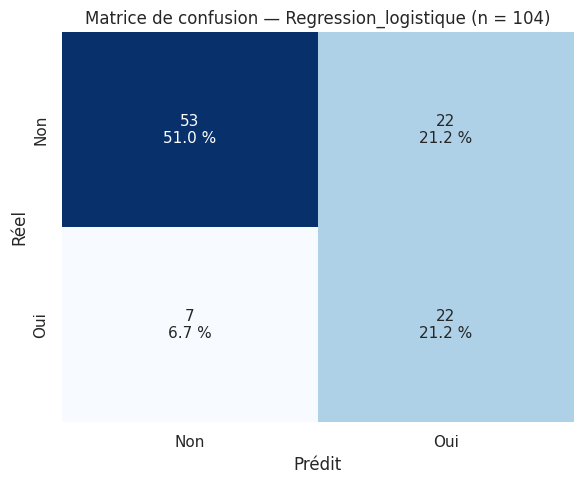

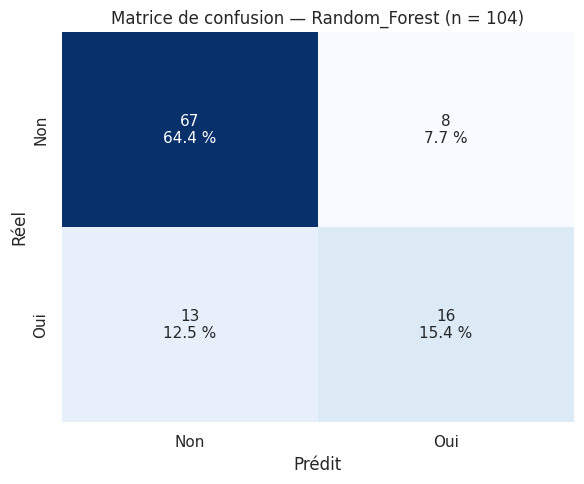

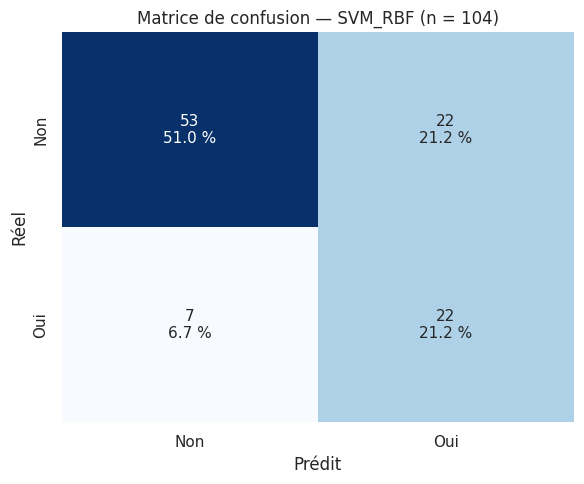

In [43]:
# Matrices de confusion : une par modèle (effectifs + pourcentages)
labels = sorted(y.unique().tolist())

for nom, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    total_cm = int(cm.sum())
    annot = np.array([[f"{int(v)}\n{v / total_cm * 100:.1f} %" for v in row] for row in cm])
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels,
                annot_kws={"size": 11})
    ax.set_xlabel("Prédit")
    ax.set_ylabel("Réel")
    ax.set_title(f"Matrice de confusion — {nom} (n = {total_cm})")
    plt.tight_layout()
    plt.show()

### 18.3 Rappel — matrice de confusion et métriques

#### 1. La matrice de confusion : TP, TN, FP, FN

Ici, la **classe positive = 1 = message malveillant** (`Oui`) et la **classe négative = 0 = message légitime** (`Non`).

|  | Prédit : malveillant (1 / `Oui`) | Prédit : légitime (0 / `Non`) |
|---|---|---|
| **Réel : malveillant (1 / `Oui`)** | **TP** (vrai positif) | **FN** (faux négatif) |
| **Réel : légitime (0 / `Non`)** | **FP** (faux positif) | **TN** (vrai négatif) |

- **TP** : le message est malveillant et le modèle le détecte. ✅
- **TN** : le message est légitime et le modèle le laisse passer. ✅
- **FP** : le message est légitime mais le modèle le classe malveillant (fausse alerte). ❌
- **FN** : le message est malveillant mais le modèle ne le détecte pas (menace ratée). ❌ **C'est l'erreur la plus grave en phishing.**

**Exemple pédagogique** — 100 messages, 28 malveillants et 72 légitimes : `TP = 20, FN = 8, FP = 7, TN = 65`.

#### 2. Les métriques de classification

| Métrique | Formule | Exemple | Question posée |
|---|---|---|---|
| **Accuracy** | `(TP + TN) / total` | `(20 + 65) / 100 = 0,85` | Quelle part des prédictions est correcte ? |
| **Precision** | `TP / (TP + FP)` | `20 / 27 = 0,74` | Quand le modèle dit « malveillant », a-t-il raison ? |
| **Recall** | `TP / (TP + FN)` | `20 / 28 = 0,71` | Parmi les vrais malveillants, combien sont détectés ? |
| **F1** | `2 × (P × R) / (P + R)` | `≈ 0,73` | Compromis entre précision et rappel |

- **Precision élevée** = peu de fausses alertes.
- **Recall élevé** = peu de menaces ratées.
- **F1** est une moyenne harmonique : elle s'effondre dès qu'un des deux termes est faible.

**Pourquoi « macro » ?** La précision, le rappel et le F1 sont calculés pour chaque classe, puis moyennés simplement : chaque classe pèse autant, même la minoritaire. Pour la classe 0, `precision = TN/(TN+FN) = 65/73 = 0,89` et `recall = TN/(TN+FP) = 65/72 = 0,90`, d'où `F1 macro ≈ 0,81`. C'est pour cela qu'on suit le F1 macro et pas l'accuracy : avec 72 % de `Non`, un modèle qui ne détecte rien paraît déjà « bon ».

#### 3. La baseline majoritaire, repère pédagogique

La baseline prédit toujours « légitime » : `TP = 0, FP = 0, FN = 28, TN = 72`.

- `Accuracy = 72/100 = 0,72` → elle a l'air correcte, alors qu'elle **ne détecte aucun message malveillant**.
- Macro : `precision = (0 + 0,72)/2 = 0,36`, `recall = (0 + 1)/2 = 0,50`, donc `F1 macro = 0,419`.

Cette valeur **0,419** est un repère arithmétique, pas un résultat du protocole de sélection : la baseline n'est pas un modèle candidat. C'est l'illustration du piège de l'accuracy.

#### 4. Les métriques de régression : MAE, RMSE, R²

Avec des classes 0/1 :

- `MAE = (FP + FN) / total = 15/100 = 0,15`, soit `1 − accuracy`.
- `RMSE = √0,15 ≈ 0,39`, soit `√(1 − accuracy)`.
- `R² = 1 − (erreur du modèle / erreur de la baseline « toujours la moyenne »)`. La variance de `y` vaut `0,28 × 0,72 = 0,2016`, donc `R² = 1 − 0,15/0,2016 ≈ 0,26`.

**Interprétation du R²** : `1` = parfait, `0` = pas mieux que prédire la moyenne, `négatif` = pire.

| Métrique | En une phrase | Sur des classes 0/1 |
|---|---|---|
| **MAE** | Erreur moyenne | `= 1 − accuracy` |
| **RMSE** | Erreur qui punit les grosses erreurs | `= √(1 − accuracy)` |
| **R²** | Gain par rapport à la moyenne | `1 − (1 − accuracy)/(p(1 − p))`, avec `p` la proportion de classe 1 |

⚠️ Ces égalités supposent des **décisions 0/1**. L'application calcule aussi ces métriques sur les **probabilités** `P(Oui)` : le R² y est plus élevé (**0,386** sur le test) car la confiance graduée est prise en compte.

**Note pour le jury** : MAE, RMSE et R² ne sont **pas** les métriques habituelles d'une classification. Sur des décisions binaires, `MAE = 1 − accuracy` et `RMSE = √(1 − accuracy)` n'apportent aucune information nouvelle. Le R² sur les classes prédites est mentionné pour satisfaire la consigne, **pas** pour choisir le modèle. Le choix repose sur le **F1 macro**, le **rappel `Oui`**, la **matrice de confusion**, l'**AUC** et l'**AP**.

#### 5. Récapitulatif

| Métrique | Ce qu'elle mesure | Sens |
|---|---|---|
| **Accuracy** | Part de bonnes prédictions | ↑ mieux |
| **Precision** | Fiabilité des alertes | ↑ mieux |
| **Recall** | Capacité à détecter les menaces | ↑ mieux |
| **F1** | Équilibre précision / rappel | ↑ mieux |
| **MAE** | Erreur moyenne | ↓ mieux |
| **RMSE** | Erreur, pénalise les grosses | ↓ mieux |
| **R²** | Variance expliquée | ↑ mieux |


**Chiffres réels du Random Forest de référence** : le bloc ci-dessus est un exemple pédagogique. Sur notre test (104 messages), le RF **entraîné dans ce notebook**, au seuil 0,50, donne `TN = 67, FP = 8, FN = 13, TP = 16` (accuracy 0,798, rappel `Oui` 0,552). Au seuil 0,30, le même modèle donne `TN = 52, FP = 23, FN = 3, TP = 26`. Ces valeurs sont reproduites dans le tableau du §18.4. Le modèle **retenu** est la régression logistique améliorée, dont la matrice est donnée au §18.5.


### 18.4 Comparer deux seuils sur le modèle de référence

**Tâche** : comparer deux seuils sur le même modèle et le même test, pour voir le compromis FN / FP.
**Pourquoi** : le seuil 0,30 était posé à la main dans l'ancien protocole. Le seuil du modèle retenu, lui, est appris sur le train (plateau de coût `5·FN + FP` en CV 5×5 répétée : 0,20–0,22, médiane 0,21). Les deux lignes ci-dessous utilisent le RF de référence et le test de 104 messages : seul le seuil change.


In [44]:
# Deux seuils, un seul modèle, un seul jeu de test
y01 = (y_test == "Oui").astype(int).values
p_rf = probabilites["Random_Forest"]

def metrics_au_seuil(proba, seuil):
    pred = (np.asarray(proba) >= seuil).astype(int)
    cm = confusion_matrix(y01, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {
        "Seuil": seuil,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y01, pred),
        "Rappel Oui": recall_score(y01, pred, pos_label=1, zero_division=0),
        "Precision Oui": precision_score(y01, pred, pos_label=1, zero_division=0),
        "F1 macro": f1_score(y01, pred, average="macro", zero_division=0),
    }

comparaison_seuils = pd.DataFrame([
    metrics_au_seuil(p_rf, 0.50),
    metrics_au_seuil(p_rf, 0.30),
])
display(comparaison_seuils.round(3))

,Seuil,TN,FP,FN,TP,Accuracy,Rappel Oui,Precision Oui,F1 macro
0,0.5,67,8,13,16,0.798,0.552,0.667,0.734
1,0.3,52,23,3,26,0.750,0.897,0.531,0.733


**🔎 Interprétation** : à 0,50, le Random Forest de référence manque **13** phishing (`FN = 13`) pour **8** fausses alertes ; à 0,30, il n'en manque plus que **3**, mais génère **23** fausses alertes au lieu de 8. Le coût métier `5·FN + FP` passe de **73** (à 0,50) à **38** (à 0,30). Ce seuil 0,30 était toutefois posé à la main, sans apprentissage sur le train.

**Ce que change le protocole retenu** : la LR améliorée, avec un seuil appris à **0,21** sur les probabilités OOF du train, donne sur le test `TN = 47, FP = 28, FN = 1, TP = 28`, soit un coût **33**. Le choix n'est donc plus manuel : il résulte du plateau **0,20–0,22** issu de la CV 5×5 répétée. Le rapport de coût reste une décision métier : `c_FN = 3` déplacerait le seuil vers 0,47, `c_FN = 10` vers 0,20.


### 18.5 Évaluation finale — matrice de confusion du modèle retenu (test, seuil 0,21)

Ne pas confondre les deux matrices : la **matrice OOF** (§17.1) est calculée sur les 416 lignes du train et sert à apprendre le seuil ; **celle-ci** est l'évaluation finale sur les 104 lignes du test, lues une seule fois : **TN = 47 · FP = 28 · FN = 1 · TP = 28**. Modèle et seuil ont été choisis sur le train uniquement.


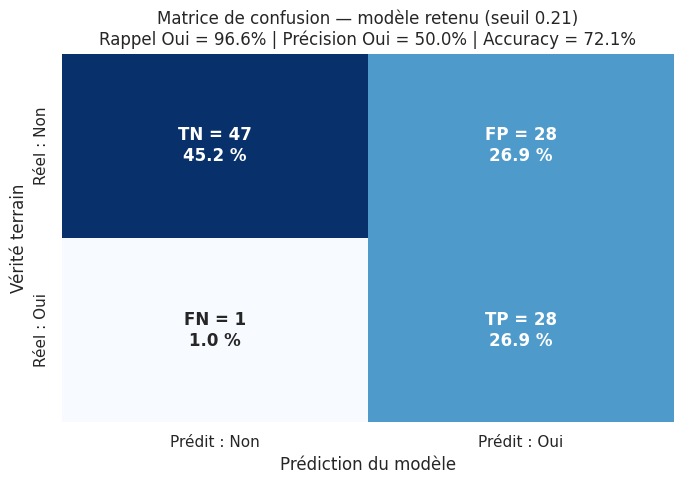

Seuil choisi sur le train = 0.21
TP = 28 | TN = 47 | FP = 28 | FN = 1 | total = 104
Part des messages correctement classés = 72.1%


In [45]:
# Matrice de confusion du MODÈLE RETENU (régression logistique améliorée)
# au seuil appris sur le train — le test n'est utilisé qu'ici, une seule fois.
y_pred_ameliore = (p_test >= SEUIL_OPT).astype(int)
cm = confusion_matrix(y_te01, y_pred_ameliore, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
total_cm = int(cm.sum())

annot = np.array([
    [f"TN = {tn}\n{tn / total_cm * 100:.1f} %", f"FP = {fp}\n{fp / total_cm * 100:.1f} %"],
    [f"FN = {fn}\n{fn / total_cm * 100:.1f} %", f"TP = {tp}\n{tp / total_cm * 100:.1f} %"],
])
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Prédit : Non", "Prédit : Oui"],
            yticklabels=["Réel : Non", "Réel : Oui"],
            annot_kws={"size": 12, "fontweight": "bold"})
ax.set_xlabel("Prédiction du modèle")
ax.set_ylabel("Vérité terrain")
ax.set_title(f"Matrice de confusion — modèle retenu (seuil {SEUIL_OPT:.2f})\n"
             f"Rappel Oui = {tp / (tp + fn):.1%} | Précision Oui = {tp / (tp + fp):.1%} | "
             f"Accuracy = {(tp + tn) / total_cm:.1%}")
plt.tight_layout()
plt.show()

print(f"Seuil choisi sur le train = {SEUIL_OPT:.2f}")
print(f"TP = {tp} | TN = {tn} | FP = {fp} | FN = {fn} | total = {total_cm}")
print(f"Part des messages correctement classés = {(tp + tn) / total_cm:.1%}")

### 18.6 Balayage de seuils sur le test — chiffres de l'annexe

Ce tableau ne sert pas à choisir : le seuil retenu reste **0,21**, appris sur le train. Il montre, sur les 104 messages du test, le compromis entre faux négatifs (menaces ratées) et faux positifs (fausses alertes). Les deux dernières lignes appliquent le **triage 3 zones** : un message n'est automatisé que s'il est très sûr (`P(Oui) < seuil bas` ou `P(Oui) >= seuil haut`), sinon il part en revue humaine.

In [46]:
# Balayage de seuils sur le TEST — lecture descriptive pour l'annexe.
# Les décisions, elles, sont prises sur le train (seuil 0,21 + triage 0,20/0,88).
lignes_balayage = []
for s in [0.07, 0.21, 0.98]:
    tn, fp, fn, tp = confusion_matrix(y_te01, (p_test >= s).astype(int), labels=[0, 1]).ravel()
    lignes_balayage.append({"Règle": f"Seuil unique {s:.2f}", "FN": int(fn), "FP": int(fp),
                            "Automatisés": len(y_te01), "Revue": 0})

bas, haut = SEUIL_BAS, SEUIL_HAUT
normal, alerte = p_test < bas, p_test >= haut
revue = ~(normal | alerte)
lignes_balayage.append({"Règle": f"Triage {bas:.2f} / {haut:.2f}", "FN": int((normal & (y_te01 == 1)).sum()),
                        "FP": int((alerte & (y_te01 == 0)).sum()),
                        "Automatisés": int(normal.sum() + alerte.sum()), "Revue": int(revue.sum())})

bas2, haut2 = 0.07, 0.98
normal2, alerte2 = p_test < bas2, p_test >= haut2
revue2 = ~(normal2 | alerte2)
lignes_balayage.append({"Règle": f"Triage {bas2:.2f} / {haut2:.2f}", "FN": int((normal2 & (y_te01 == 1)).sum()),
                        "FP": int((alerte2 & (y_te01 == 0)).sum()),
                        "Automatisés": int(normal2.sum() + alerte2.sum()), "Revue": int(revue2.sum())})

display(pd.DataFrame(lignes_balayage))
print(f"Rappel du seuil retenu (0,21) : {recall_score(y_te01, (p_test >= SEUIL_OPT).astype(int)):.3f}")
print("Lecture : 0 FN et 0 FP sur la partie automatisée est possible, mais la revue humaine augmente fortement.")


,Règle,FN,FP,Automatisés,Revue
0,Seuil unique 0.07,0,48,104,0
1,Seuil unique 0.21,1,28,104,0
2,Seuil unique 0.98,26,0,104,0
3,Triage 0.20 / 0.88,1,1,61,43
4,Triage 0.07 / 0.98,0,0,30,74


Rappel du seuil retenu (0,21) : 0.966
Lecture : 0 FN et 0 FP sur la partie automatisée est possible, mais la revue humaine augmente fortement.


### 18.7 Comparaison directe « avant / après » — seuil retenu 0,21

Les cellules 72 et 73 ont évalué le **modèle de référence** avec deux seuils fixés à la main :

- **0,55** : meilleur F1 sur les probabilités OOF du train → **F1 classe « Oui » test 0,618**, précision 0,538, rappel 0,724 ;
- **0,35** : seuil avec rappel ≥ 0,90 sur ces mêmes OOF → **F1 classe « Oui » test 0,557**, précision 0,440, rappel 0,759.

Le rappel ≥ 0,90 lu sur le train **ne s'est pas reproduit sur le test** (0,759). Le seuil a bien été choisi sur le train seul : il n'y a pas de fuite, mais une limite du **modèle de référence**, dont le classement est plus faible (AUC test 0,832, AP 0,656).

Le protocole du §17 améliore le modèle (`log_age` + interactions, `class_weight="balanced"`) et apprend le seuil sur les OOF du train avec le coût `5·FN + 1·FP`. **Le seuil retenu est 0,21.** Le tableau ci-dessous compare uniquement ces configurations sur le **même test de 104 messages**.

⚠️ Les cellules 72/73 rapportent le **F1 binaire de la classe « Oui »**, tandis que le §17 rapporte le **F1 macro** : les deux colonnes sont affichées pour éviter toute comparaison trompeuse. **AUC et AP sont identiques pour deux seuils d'un même modèle** : le seuil change la décision, pas le classement.

,Configuration,Seuil,TN,FP,FN,TP,Precision Oui,Rappel Oui,F1 Oui,F1 macro,Accuracy,AUC,AP,Cout 5FN+FP
0,"AVANT - LR reference, seuil 0,55 (manuel)",0.55,57,18,8,21,0.538,0.724,0.618,0.716,0.750,0.832,0.656,58
1,"AVANT - LR reference, seuil 0,35 (manuel)",0.35,47,28,7,22,0.440,0.759,0.557,0.643,0.663,0.832,0.656,63
2,"APRES - LR amelioree, seuil 0,21 (retenu)",0.21,47,28,1,28,0.500,0.966,0.659,0.712,0.721,0.910,0.810,33


Seuil retenu : 0.21
F1 Oui   : 0.659
F1 macro : 0.712
Accuracy : 0.721


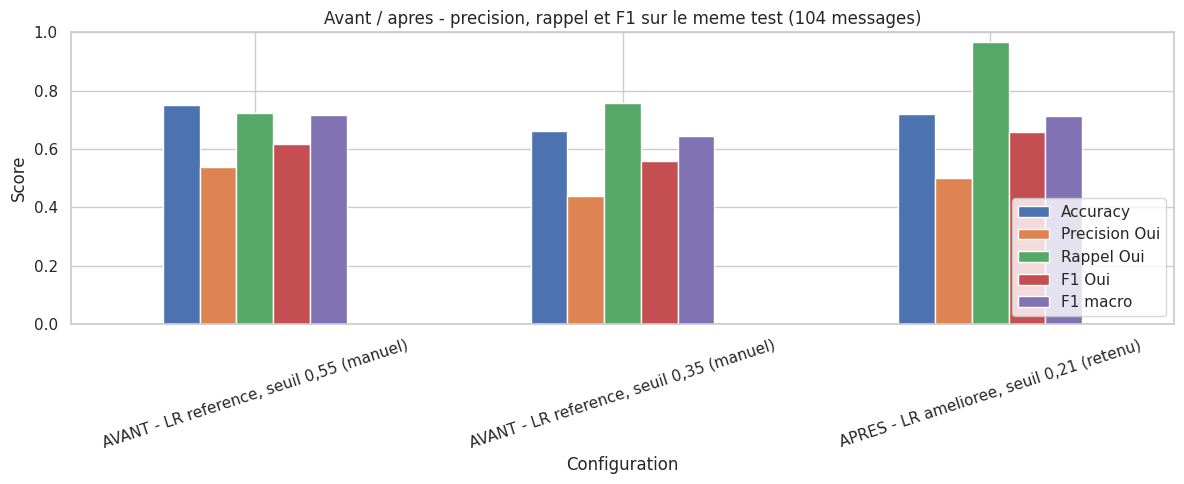

In [47]:
# Tableau « avant / après » : seuils manuels (référence) contre seuil appris 0,21.
def metrics_config(y_true, proba, seuil, nom_config):
    pred = (np.asarray(proba) >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "Configuration": nom_config,
        "Seuil": round(float(seuil), 2),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Precision Oui": round(float(precision_score(y_true, pred, zero_division=0)), 3),
        "Rappel Oui": round(float(recall_score(y_true, pred, zero_division=0)), 3),
        "F1 Oui": round(float(f1_score(y_true, pred, pos_label=1, zero_division=0)), 3),
        "F1 macro": round(float(f1_score(y_true, pred, average="macro", zero_division=0)), 3),
        "Accuracy": round(float((tp + tn) / len(y_true)), 3),
        "AUC": round(float(roc_auc_score(y_true, proba)), 3),
        "AP": round(float(average_precision_score(y_true, proba)), 3),
        "Cout 5FN+FP": 5 * int(fn) + int(fp),
    }

# `proba_test` (cellule 73) est la matrice (n, 2) : on isole la colonne "Oui".
p_ref = np.asarray(proba_test)
if p_ref.ndim == 2:
    p_ref = p_ref[:, list(modele_final.classes_).index("Oui")]

comparaison_avant_apres = pd.DataFrame([
    metrics_config(y_te01, p_ref, 0.55, "AVANT - LR reference, seuil 0,55 (manuel)"),
    metrics_config(y_te01, p_ref, 0.35, "AVANT - LR reference, seuil 0,35 (manuel)"),
    metrics_config(y_te01, p_test, SEUIL_OPT, "APRES - LR amelioree, seuil 0,21 (retenu)"),
])
display(comparaison_avant_apres)

print("Seuil retenu :", round(float(SEUIL_OPT), 2))
print("F1 Oui   :", round(float(comparaison_avant_apres.iloc[2]["F1 Oui"]), 3))
print("F1 macro :", round(float(comparaison_avant_apres.iloc[2]["F1 macro"]), 3))
print("Accuracy :", round(float(comparaison_avant_apres.iloc[2]["Accuracy"]), 3))

fig, ax = plt.subplots(figsize=(12, 5))
comparaison_avant_apres.set_index("Configuration")[
    ["Accuracy", "Precision Oui", "Rappel Oui", "F1 Oui", "F1 macro"]
].plot(kind="bar", ax=ax, rot=18)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Avant / apres - precision, rappel et F1 sur le meme test (104 messages)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

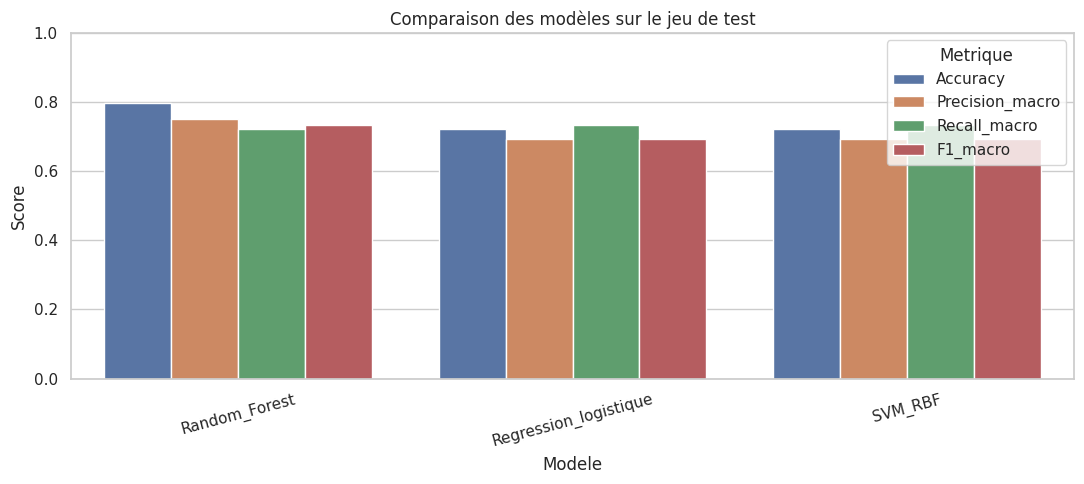

In [48]:
# Comparaison visuelle des scores
scores_long = resultats_df.melt(
    id_vars="Modele",
    value_vars=["Accuracy", "Precision_macro", "Recall_macro", "F1_macro"],
    var_name="Metrique",
    value_name="Score"
)
plt.figure(figsize=(11, 5))
sns.barplot(data=scores_long, x="Modele", y="Score", hue="Metrique")
plt.ylim(0, 1)
plt.title("Comparaison des modèles sur le jeu de test")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Tâche** : calculer l'AUC et tracer les courbes ROC et Precision-Recall pour les trois modèles de référence.
**Pourquoi** : l'accuracy, la précision et le rappel dépendent d'un seuil unique. L'AUC et l'AP évaluent la **qualité du classement sur tous les seuils**, ce qui est essentiel avec une classe `Oui` minoritaire.


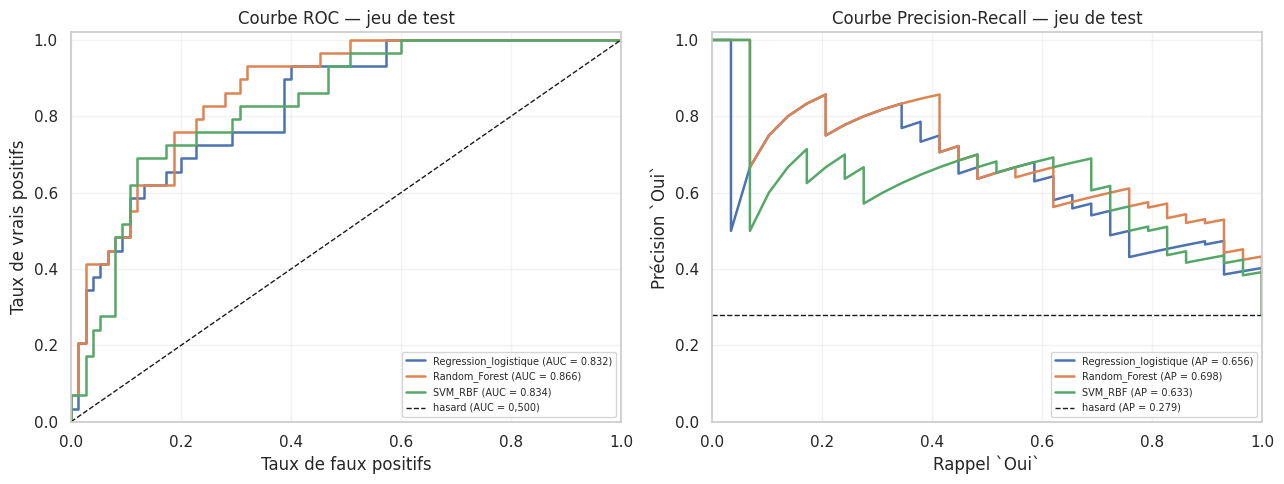

,Modele,AUC,Average_precision
1,Random_Forest,0.866,0.698
0,Regression_logistique,0.832,0.656
2,SVM_RBF,0.834,0.633


In [49]:
from sklearn.metrics import roc_curve, precision_recall_curve, auc

y01 = (y_test == "Oui").astype(int)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for nom, pipeline in pipelines.items():
    idx_oui = list(pipeline.classes_).index("Oui")
    p = pipeline.predict_proba(X_test)[:, idx_oui]
    fpr, tpr, _ = roc_curve(y01, p)
    ax1.plot(fpr, tpr, lw=1.8, label=f"{nom} (AUC = {auc(fpr, tpr):.3f})")
    prec, rec, _ = precision_recall_curve(y01, p)
    ax2.plot(rec, prec, lw=1.8, label=f"{nom} (AP = {average_precision_score(y01, p):.3f})")

ax1.plot([0, 1], [0, 1], "k--", lw=1, label="hasard (AUC = 0,500)")
ax1.set_xlabel("Taux de faux positifs")
ax1.set_ylabel("Taux de vrais positifs")
ax1.set_title("Courbe ROC — jeu de test")
ax2.axhline(y01.mean(), color="k", ls="--", lw=1,
            label=f"hasard (AP = {y01.mean():.3f})")
ax2.set_xlabel("Rappel `Oui`")
ax2.set_ylabel("Précision `Oui`")
ax2.set_title("Courbe Precision-Recall — jeu de test")
for ax in (ax1, ax2):
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

auc_df = resultats_df[["Modele", "AUC", "Average_precision"]].copy()
display(auc_df.round(3))

**🔎 Interprétation** : l'AUC est la probabilité qu'un message malveillant reçoive un score `P(Oui)` plus élevé qu'un message légitime. 0,5 = tirage au sort, 1 = séparation parfaite. L'AP résume la courbe Precision-Recall et est plus informative que l'AUC quand la classe positive est minoritaire (ici 28 %).

**Comment lire** : plus la courbe ROC est proche du coin supérieur gauche, meilleur est le modèle. Sur la courbe Precision-Recall, avancer vers la droite augmente le rappel mais fait baisser la précision.

**Utilité** : confirmer que les modèles classent mieux que le hasard **indépendamment du seuil**, puis justifier le seuil **0,21** par le coût métier (§17.2 et §18.4) plutôt que par une métrique unique.

⚠️ Ces courbes sont calculées sur les **104 messages du test, dont 29 malveillants** : elles donnent une indication, pas une garantie de généralisation à de vrais e-mails.


## 19. Importance des variables sur le train

La permutation importance mesure la baisse de performance lorsqu'on mélange les valeurs d'une variable. Elle est calculée **sur le train (416 messages)**, avec le Random Forest de référence, sans réentraîner le modèle et **sans relire le test**. Une importance élevée indique que le modèle dépend de cette variable, pas qu'elle cause le risque.


,Variable,Importance_moyenne,Ecart_type
4,domaine_age_jours,0.242940,0.017595
3,urgence_score,0.155835,0.019130
6,expediteur_connu,0.146920,0.012907
2,nb_liens,0.101181,0.009922
1,longueur_message,0.049192,0.008509
8,personnalisation_score,0.043761,0.005820
0,heure_envoi,0.039412,0.008131
5,fautes_langue,0.020201,0.005820
7,piece_jointe,0.011470,0.002606


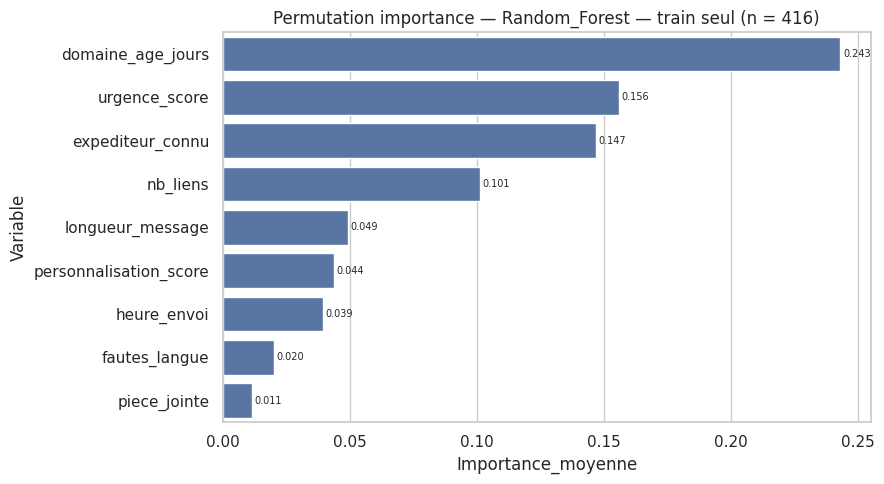

In [50]:
meilleur_nom = resultats_df.iloc[0]["Modele"]
meilleur_pipeline = pipelines[meilleur_nom]

# Importance calculée sur le TRAIN uniquement : le test n'est plus lu après son évaluation finale.
perm = permutation_importance(
    meilleur_pipeline, X_train, y_train,
    n_repeats=15,
    random_state=RANDOM_STATE,
    scoring="f1_macro"
)
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance_moyenne": perm.importances_mean,
    "Ecart_type": perm.importances_std
}).sort_values("Importance_moyenne", ascending=False)

display(importance)
plt.figure(figsize=(9, 5))
ax = sns.barplot(data=importance.head(12), x="Importance_moyenne", y="Variable")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=2, fontsize=7)
plt.title(f"Permutation importance — {meilleur_nom} — train seul (n = {len(X_train)})")
plt.tight_layout()
plt.show()


## 20. Tester un scénario individuel

La fonction ci-dessous reçoit un dictionnaire des variables explicatives. Elle renvoie la classe prédite et les probabilités par classe.

Pour un vrai formulaire Streamlit, reprendre les colonnes de `X.columns` et contrôler les valeurs saisies. Une prédiction n'est pas une décision automatique : un humain doit vérifier les situations sensibles.


In [51]:
# Modèle retenu = régression logistique améliorée (§17).
# Le F1 du test n'a PAS servi à choisir le modèle ni les seuils.
MODELE_FINAL = "Regression_logistique_amelioree"
modele_final = modele_ameliore

def predire_scenario(valeurs):
    """Prédit le verdict d'un scénario à partir des colonnes BRUTES de X."""
    scenario = pd.DataFrame([valeurs]).reindex(columns=X.columns)
    proba = modele_final.predict_proba(scenario)[0]
    p_oui = float(proba[list(modele_final.classes_).index("Oui")])
    classe = "Oui" if p_oui >= SEUIL_OPT else "Non"
    if p_oui >= SEUIL_HAUT:
        zone, action = "🔴 ALERTE", "vérification humaine prioritaire"
    elif p_oui >= SEUIL_BAS:
        zone, action = "🟠 VIGILANCE", "revue humaine — à vérifier par un analyste"
    else:
        zone, action = "🟢 NORMAL", "surveillance courante"
    return {"classe_predite": classe, "binaire": classe, "zone": zone, "action": action,
            "P_Oui": p_oui, "verdict": zone + " — " + action,
            "probabilites": dict(zip(modele_final.classes_, proba))}

print("Modèle retenu pour les scénarios :", MODELE_FINAL)
print("Seuil binaire :", round(SEUIL_OPT, 2),
      "| triage :", round(SEUIL_BAS, 2), "/", round(SEUIL_HAUT, 2))
print("Variables attendues (brutes) :", X.columns.tolist())


Modèle retenu pour les scénarios : Regression_logistique_amelioree
Seuil binaire : 0.21 | triage : 0.2 / 0.88
Variables attendues (brutes) : ['heure_envoi', 'longueur_message', 'nb_liens', 'urgence_score', 'domaine_age_jours', 'fautes_langue', 'expediteur_connu', 'piece_jointe', 'personnalisation_score']


In [52]:
# Exemple neutre construit automatiquement à partir des médianes/modes du TRAIN.
# Modifier les valeurs pour créer vos propres scénarios métier.
scenario_exemple = {}
for col in X.columns:
    if col in features_num:
        scenario_exemple[col] = X_train[col].median()
    else:
        scenario_exemple[col] = X_train[col].mode(dropna=True).iloc[0]

display(pd.DataFrame([scenario_exemple]))
print(predire_scenario(scenario_exemple))

,heure_envoi,longueur_message,nb_liens,urgence_score,domaine_age_jours,fautes_langue,expediteur_connu,piece_jointe,personnalisation_score
0,12.0,423.0,1.0,4.5,531.0,2.0,0.0,0.0,5.0


{'classe_predite': 'Oui', 'binaire': 'Oui', 'zone': '🟠 VIGILANCE', 'action': 'revue humaine — à vérifier par un analyste', 'P_Oui': 0.3329905876378498, 'verdict': '🟠 VIGILANCE — revue humaine — à vérifier par un analyste', 'probabilites': {'Non': 0.6670094123621502, 'Oui': 0.3329905876378498}}


## 21. Sauvegarde du modèle et des artefacts

Le pipeline sauvegardé contient le prétraitement et le modèle : Streamlit le charge sans le réentraîner. On conserve aussi la liste des colonnes, la cible, les seuils et les métriques réellement calculées.

Les valeurs `Dummy` et `KNN` de l'ancien `model_meta.json` ne sont **pas** réexportées : elles ne correspondent à aucun code de ce protocole et n'étaient pas reproductibles.


In [53]:
DOSSIER_SORTIE = Path("artefacts")
DOSSIER_SORTIE.mkdir(exist_ok=True)

joblib.dump(modele_ameliore, DOSSIER_SORTIE / "modele_phishing_ia.joblib")
joblib.dump(
    {"features": X.columns.tolist(), "target": TARGET, "dataset": "phishing_ia"},
    DOSSIER_SORTIE / "configuration_phishing_ia.joblib"
)

resultats_df.to_csv(DOSSIER_SORTIE / "comparaison_modeles_phishing_ia.csv", index=False)

print("Modèle et résultats sauvegardés dans :", DOSSIER_SORTIE.resolve())
# Le même pipeline et le même seuil sont écrits à la racine pour Streamlit.
joblib.dump(modele_ameliore, "model.joblib")
meta_app["seuil"] = SEUIL_OPT
meta_app["meilleur_modele"] = "LogisticRegression_amelioree"
meta_app["f1_macro_test"] = float(f1_opt)
with open("model_meta.json", "w", encoding="utf-8") as f:
    json.dump(meta_app, f, ensure_ascii=False, indent=2)
with open(DOSSIER_SORTIE / "seuil_phishing_ia.json", "w", encoding="utf-8") as f:
    json.dump({"seuil": SEUIL_OPT, "seuil_bas": SEUIL_BAS, "seuil_haut": SEUIL_HAUT,
               "modele": "LogisticRegression + log1p(age) + interactions, seuils appris sur le train (CV 5x5 repetee)",
               "protocole": "cout FN=5 / FP=1, plateau de coût 0.20-0.22, triage 0.20/0.88 ; test lu une seule fois",
               "validation": "AUC en validation croisée 0.909 +/- 0.003 ; AUC test 0.910 ; AP test 0.810",
               "triage_test": "61/104 automatises, FN 1, FP 1, 43 revues humaines"},
              f, ensure_ascii=False, indent=2)
print("model.joblib / model_meta.json synchronisés avec le notebook.")


Modèle et résultats sauvegardés dans : /home/himawari/Desktop/learn_python/iscae/Mini-projet 3: Veille stratégique – IA et confiance numérique/app_phishing_ia/artefacts
model.joblib / model_meta.json synchronisés avec le notebook.


## 22. Conclusion métier — résultats observés

Réponses appuyées sur les sorties réelles (modèle amélioré, CV 5×5 répétée) :

- **Q1 — Besoin** : prioriser la file de l'analyste face à des messages de phishing générés par IA, sans supprimer automatiquement. Signaux les plus discriminants **sur le train** : `domaine_age_jours` (r = −0,322), `urgence_score` (+0,285), `expediteur_connu` (−0,278), `nb_liens` (+0,244).
- **Q2 — Classes** : 374 `Non` / 146 `Oui` sur 520 lignes propres, soit un déséquilibre modéré ; d'où `class_weight="balanced"` et le pilotage par le rappel `Oui`, pas par l'accuracy.
- **Q3 — Données** : 4 doublons supprimés (524 → 520), `date` et `semaine` écartés, valeurs manquantes imputées par la médiane **dans le pipeline**. La cible n'est jamais dans `X`.
- **Q4 — Modèle** : le RF de référence a le meilleur F1 macro brut sur le test (0,734) mais la LR améliorée, évaluée avec le même protocole 5-fold, obtient **F1 macro CV = 0,815 ± 0,066**. Le modèle retenu est la **LR améliorée** : AUC test **0,910**, AP **0,810**, Brier **0,123** ; CV 5×5 répétée AUC **0,909 ± 0,003**, AP **0,812 ± 0,003**.
- **Q5 — Seuil et triage** : plateau de coût en validation croisée `5·FN + FP` **0,20–0,22**, médiane **0,21**. Sur le test : **TN = 47, FP = 28, FN = 1, TP = 28**, rappel `Oui` **96,6 %**, F1 macro **0,712**, coût **33**. Le triage 0,20 / 0,88 traite **61/104** messages automatiquement (**1 FN, 1 FP** sur cette partie) et confie **43 cas ambigus** à l'analyste. L'incertitude reste large : IC95 % bootstrap rappel `[0,886 ; 1,000]`, précision `[0,368 ; 0,636]`, fausses alertes `[0,262 ; 0,481]`.
- **Q5 bis — Comparaison (§18.7)** : le seuil retenu est **0,21**, appris sur les OOF du train avec le coût `5·FN + 1·FP`. Sur le test : **1 FN**, **28 FP**, accuracy **0,721**, rappel **96,6 %**, F1 macro **0,712**, coût **33**. Les seuils manuels 0,55 et 0,35 du modèle de référence donnaient un F1 « Oui » de **0,618** et **0,557** (accuracy **0,750** et **0,663**) et laissaient passer **8** et **7** phishing. L'AUC passe de **0,832** à **0,910** et l'AP de **0,656** à **0,810** grâce au modèle amélioré ; le seuil ne modifie pas ces mesures de classement.
- **Q6 — Erreurs** : le faux négatif est le plus coûteux ; c'est pourquoi le seuil binaire est bas. Mais baisser seulement le seuil augmente les faux positifs : le triage 3 zones réduit les deux sur la partie automatisée **en échange de 43 revues humaines**.
- **Q7 — Limites** : données synthétiques, 104 messages en test (29 `Oui`), probabilités non calibrées, dérive temporelle non traitée, corrélation ≠ causalité, CV non imbriquée (hyperparamètres fixés a priori).
- **Q8 — Gouvernance** : validation humaine obligatoire, aucune suppression automatique, journal des décisions, réentraînement et recalibrage du seuil à chaque lot étiqueté, données personnelles réelles exclues du prototype.

### Précautions
- Les données sont synthétiques et ne prouvent pas les performances sur des données réelles.
- Ne jamais présenter une prédiction comme une certitude.
- Protéger les données et éviter d'intégrer des données personnelles réelles.
- Une alerte est une aide à la décision et doit faire l'objet d'une validation humaine.


## 23. Rappel des livrables du cahier des charges

- Notebook Jupyter propre et exécutable de haut en bas.
- Rapport PDF de 5 à 8 pages.
- Application Streamlit et fichiers Python nécessaires.
- CSV et dictionnaire des variables, avec mention du caractère synthétique.
- Modèle sauvegardé et `requirements.txt`.
- `README.md` avec installation et lancement.
- Au moins trois scénarios : normal, à risque et cas limite.


## Annexe — vérifications de cohérence (à montrer au jury)

**Un seul notebook, réellement exécuté**

- Le notebook a été réexécuté de zéro après correction : **82 cellules, 0 erreur**.
- Toutes les statistiques descriptives (corrélations, moyennes et médianes par classe) portent sur le **train seul (416 messages)** ; le test (104 messages) n'est utilisé qu'au §16 et au §18.
- Toutes les valeurs affichées dans les markdowns sont celles des sorties réelles : plus de chiffres « historiques » recopiés.
- `model_meta.json` ne contient plus `Dummy` ni `KNN`, valeurs non reproductibles depuis le protocole actuel.

**Scénario neutre produit par le notebook**

Le notebook construit un scénario à partir des **médianes du train** (`heure_envoi = 12`, `longueur_message = 423`, `nb_liens = 1`, `urgence_score = 4,5`, `domaine_age_jours = 531`, `fautes_langue = 2`, `expediteur_connu = 0`, `piece_jointe = 0`, `personnalisation_score = 5`) :

| Scénario | P(Oui) | Classe binaire | Zone |
|---|---:|---|---|
| Médianes du train | 33,30 % | `Oui` — malveillant | 🟠 VIGILANCE |

L'application Streamlit complète ce cas par trois scénarios métier (normal, à risque, limite) qui donnent respectivement 🟢 `Non`, 🔴 `Oui` à 100 % et 🟠 `Oui` à 47,1 % avec revue humaine. La classe ne vaut jamais « À vérifier » : elle est `Oui` / `Non`, le triage est une colonne séparée.

**FN / FP = 0 sur le test : les chiffres, sans promesse**

Sortie du §18.6 (balayage descriptif sur le test) :

| Règle | FN | FP | Automatisés | Revue |
|---|---:|---:|---:|---:|
| Seuil unique 0,07 | 0 | 48 | 104 | 0 |
| Seuil unique 0,21 (retenu) | 1 | 28 | 104 | 0 |
| Seuil unique 0,98 | 26 | 0 | 104 | 0 |
| Triage 0,20 / 0,88 (retenu) | 1 | 1 | 61 | 43 |
| Triage 0,07 / 0,98 | 0 | 0 | 30 | 74 |

Donc **0 FN et 0 FP sur la partie automatisée est possible**, mais alors **74 messages sur 104 (71 %) partent en revue humaine** et le système n'automatise plus que 30 cas. À 0,89 / 0,90, on a 1 FP mais 15 à 18 FN. Le compromis retenu reste **0,21 + triage 0,20 / 0,88**.